# 01 – Exploratory Data Analysis

TDT4173 project – SINTEF Tokke–Vinje unit commitment

**Goal:** understand the data before modelling. Structure follows the EDA lecture and the graded EDA items:

| Graded EDA item | Section |
|---|---|
| Search domain knowledge | 2.1 |
| Understand how the data was generated | 2.2 |
| Check if the data is intuitive | 2.3 |
| Explore individual features | 3 |
| Explore pairs and groups of features | 4 |
| Clean up features | 5 |

## 0. Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "../data"
KERNEL_DIR = f"{DATA_DIR}/kernel"
EXTENDED_DIR = f"{DATA_DIR}/extended"

## 1. Load data

### 1.1 Target: unit commitment decisions

- Train: 2922 rows × 2355 columns. One row = one run (one weekly plan), one run per day from 2015-01-01 to 2022-12-31.
- Columns: `Run No`, `starttime`, `total_calculation_time` + 2352 targets (14 generators × 168 hours).
- Target values are 0/1 (off/on). In the first days of 2015, Hogga G1 is on in every hour shown.
- `total_calculation_time` (~40–56 s) is not available for test → cannot be used as a feature.
- Test: 725 rows × 2353 columns (`Run No` + the same 2352 targets, filled with 0 as a template).


In [3]:
train = pd.read_csv(f"{KERNEL_DIR}/Unit_commitment_decisions.csv", parse_dates=["starttime"])
test = pd.read_csv("../sample_submission.csv")

print(train.shape, test.shape)
train.head()

(2922, 2355) (725, 2353)


,Run No,starttime,total_calculation_time,result_committed_Hogga_G1_t0,result_committed_Hogga_G1_t1,result_committed_Hogga_G1_t2,result_committed_Hogga_G1_t3,result_committed_Hogga_G1_t4,result_committed_Hogga_G1_t5,result_committed_Hogga_G1_t6,...,result_committed_Vesle Kjela_G1_t158,result_committed_Vesle Kjela_G1_t159,result_committed_Vesle Kjela_G1_t160,result_committed_Vesle Kjela_G1_t161,result_committed_Vesle Kjela_G1_t162,result_committed_Vesle Kjela_G1_t163,result_committed_Vesle Kjela_G1_t164,result_committed_Vesle Kjela_G1_t165,result_committed_Vesle Kjela_G1_t166,result_committed_Vesle Kjela_G1_t167
0,1,2015-01-01,48.950692,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,2015-01-02,56.048899,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
2,3,2015-01-03,44.280307,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
3,4,2015-01-04,40.848453,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
4,5,2015-01-05,44.036279,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0


### 1.2 Kernel features (price, inflow, volume, water value)

- Price: hourly, 2015–2025, one column (EUR/MWh).
- Inflow: hourly, 1958–2025, 17 reservoirs + 1 river. Long history, useful for seeing "normal years".
- Volume: daily, 2015–2024, 17 reservoirs.
- Water value: daily, 2015–2024, 17 reservoirs (synthetic, i.e. model-generated).
- Different time resolutions (hourly vs. daily) → must be aligned later.
- TODO: check that all tables cover the whole test period (until ~2024-12-31).

In [4]:
# Day-ahead price (hourly, EUR/MWh)
price = pd.read_csv(f"{KERNEL_DIR}/Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"])

# Inflow per reservoir (hourly, m³/s)
inflow = pd.read_csv(f"{KERNEL_DIR}/Historical_inflow_1958_2025.csv", parse_dates=["date"])

# Reservoir volume (daily, Mm³)
volume = pd.read_csv(f"{KERNEL_DIR}/Historical_volume_2015_2024.csv", parse_dates=["date"])

# Water value per reservoir (daily, EUR/MWh)
water_value = pd.read_csv(f"{KERNEL_DIR}/Synthetic_water_value_2015_2024.csv", parse_dates=["date"])

for name, df in {"price": price, "inflow": inflow, "volume": volume, "water_value": water_value}.items():
    print(f"{name:12s} shape={df.shape}  from {df['date'].min()} to {df['date'].max()}")

price.head(), inflow.head(), volume.head(), water_value.head()

price        shape=(103062, 2)  from 2015-01-01 00:00:00+00:00 to 2025-12-31 23:45:00+00:00
inflow       shape=(594224, 19)  from 1958-01-01 00:00:00+00:00 to 2025-10-15 07:00:00+00:00
volume       shape=(3654, 18)  from 2015-01-01 00:00:00+00:00 to 2025-01-01 00:00:00+00:00
water_value  shape=(3654, 18)  from 2015-01-01 00:00:00+00:00 to 2025-01-01 00:00:00+00:00


(                       date  Day-ahead price (EUR/MWh)
 0 2015-01-01 00:00:00+00:00                      27.07
 1 2015-01-01 01:00:00+00:00                      26.93
 2 2015-01-01 02:00:00+00:00                      26.83
 3 2015-01-01 03:00:00+00:00                      26.81
 4 2015-01-01 04:00:00+00:00                      26.97,
                        date  Langesae  Staavatn  Kjelavatn  Bordalsvatn  \
 0 1958-01-01 00:00:00+00:00      0.37      0.03       1.23          0.5   
 1 1958-01-01 01:00:00+00:00      0.37      0.03       1.23          0.5   
 2 1958-01-01 02:00:00+00:00      0.37      0.03       1.23          0.5   
 3 1958-01-01 03:00:00+00:00      0.37      0.03       1.23          0.5   
 4 1958-01-01 04:00:00+00:00      0.37      0.03       1.23          0.5   
 
    Foersvatn  Hyljelihyl  Venemo  Bitdalsvatn  Songavatn  Totak  Vaamarvatn  \
 0       0.05        0.34    0.37         1.07       4.92   3.28        0.21   
 1       0.05        0.34    0.37         1.0

### 1.3 Extended data (topology, min flow, min volume)

- min_flow: 96432 rows (hourly 2015–2025) × 6 rivers with minimum flow requirements.
- min_volume: 96432 rows × 3 reservoirs (Totak, Byrtevatn, Staavatn) with minimum level requirements.
- Both cover train and test completely.
- Topology has 5 sections: reservoir, river, plant, generator, tunnel.
- The 14 generators in the topology are exactly the same as the 14 in the target → the files match.
- The topology gives p_min/p_max, start cost, and which reservoir feeds which plant → useful for feature engineering.

In [5]:
import yaml
# Constraints (hourly)
min_flow = pd.read_csv(f"{EXTENDED_DIR}/Constraint_min_flow.csv", parse_dates=["date"])
min_volume = pd.read_csv(f"{EXTENDED_DIR}/Constraint_min_volume.csv", parse_dates=["date"])

# Topology: the physical network
with open(f"{EXTENDED_DIR}/Tokke_Vinje_topology.yaml") as f:
    topology = yaml.safe_load(f)

print(min_flow.shape, min_volume.shape)
print("Topology sections:", list(topology["model"].keys()))
print("Generators:", list(topology["model"]["generator"].keys()))

(96432, 7) (96432, 4)
Topology sections: ['reservoir', 'river', 'plant', 'generator', 'tunnel']
Generators: ['Hogga_G1', 'Tokke_G1', 'Tokke_G2', 'Tokke_G3', 'Tokke_G4', 'Lio_G1', 'Byrte_G1', 'Vinje_G1', 'Vinje_G2', 'Vinje_G3', 'Haukeli_G1', 'Songa_G1', 'Kjela_G1', 'Vesle Kjela_G1']


### 1.4 Test set / sample submission

- Test = 725 runs, Run No 2923–3647, consecutive with no gaps (3647 − 2923 + 1 = 725).
- The test file has no dates, only Run No.
- Test has no dates, so here we check which Run Nos it contains. The dates are worked out in 2.2.2."
- In train, Run No n = 2015-01-01 + (n−1) days. [Check: did the pattern hold? True/False] - true, see 2.2.2
- Using the same pattern, test covers 2023-01-01 → 2024-12-25 (the last run extends to ~2024-12-31).
- The test period directly follows train → time series split; validation should also be done in time order

In [6]:
test[["Run No"]].describe()

,Run No
count,725.00000
mean,3285.00000
std,209.43376
min,2923.00000
25%,3104.00000
50%,3285.00000
75%,3466.00000
max,3647.00000


## 2. Building intuition about the data

### 2.1 Domain knowledge

*Hydropower basics, water value (price vs. water value rule), day-ahead market (NO2), unit commitment (start costs, p_min/p_max), seasons, constraints, the Tokke–Vinje topology.*

### 2.2 How the data was generated

**Where the target comes from**
- The on/off decisions are not observed operation. They are the output of a hydropower scheduling **optimisation model** (most likely SINTEF's SHOP).
- Each `Run No` is one run of the model: given prices, inflow, start volumes, water values and constraints, it computes the most profitable on/off plan for the next **168 hours** for all 14 generators.
- Our ML model is therefore learning to **imitate an optimiser**. The targets are deterministic functions of the inputs (no human noise), but they also depend on things we do not see directly (e.g. start costs, efficiency curves, coupling between plants).

**How the runs are organised**
- One run per day: Run 1 = 2015-01-01, Run 2 = 2015-01-02, ... (verified in 2.2.2).
- Each run covers 7 days → consecutive runs **overlap** by 6 days. The same clock hour is planned by up to 7 different runs (examined in 2.2.1).
- Train = 2015–2022, test = 2023–2024. Test comes **after** train in time.

**How the input data was produced**
- Day-ahead price: real historical market prices (Nord Pool).
- Inflow and volume: historical series per reservoir.
- Water value: **synthetic**, i.e. computed by a model, not observed.
- Constraints and topology: model input describing the physical system and regulations.

**Consequences for modelling**
- **Validation must be time-based** (e.g. train 2015–2021, validate 2022). A random split would leak information because neighbouring runs share 6 of 7 days.
- `total_calculation_time` is a by-product of the optimiser and is not available for test → **not a feature**.
- Features for a run should describe the run's own 168-hour window (prices, water values, volumes at the start).

#### 2.2.1 Overlapping horizons: consistency between consecutive runs

Run *n+1* starts 24 h after run *n*, so hour `t(h+24)` in run *n* and hour `t(h)` in run *n+1* are the same clock hour. If the optimiser always made the same decision for the same hour, these would be identical.

In [7]:
gens = sorted({c.rsplit("_t", 1)[0] for c in train.columns if c.startswith("result_committed_")})
gen_names = [g.replace("result_committed_", "") for g in gens]

# Y[run, generator, hour]
Y = np.stack([train[[f"{g}_t{h}" for h in range(168)]].to_numpy() for g in gens], axis=1)
print("Y shape (runs, generators, hours):", Y.shape)

# Compare the same clock hour in run n and run n+1
same = Y[:-1, :, 24:] == Y[1:, :, :-24]
print(f"Overall agreement between consecutive runs: {same.mean():.3f}")

Y shape (runs, generators, hours): (2922, 14, 168)
Overall agreement between consecutive runs: 0.878


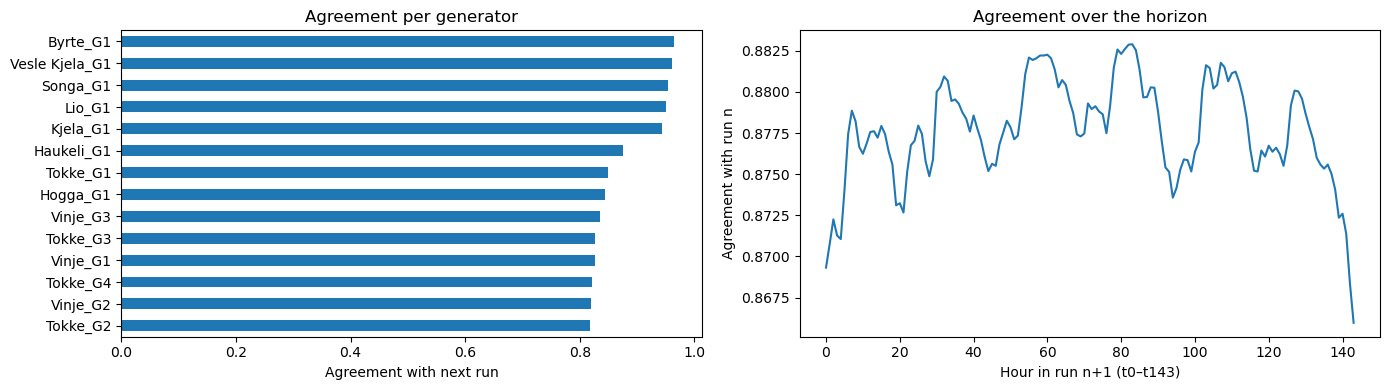

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

agree_per_gen = pd.Series(same.mean(axis=(0, 2)), index=gen_names).sort_values()
agree_per_gen.plot.barh(ax=axes[0])
axes[0].set_xlabel("Agreement with next run")
axes[0].set_title("Agreement per generator")

axes[1].plot(same.mean(axis=(0, 1)))
axes[1].set_xlabel("Hour in run n+1 (t0–t143)")
axes[1].set_ylabel("Agreement with run n")
axes[1].set_title("Agreement over the horizon")

plt.tight_layout()
plt.show()

**Notes 2.2.1**
- Consecutive runs agree on about **88%** of overlapping generator-hours → the plan for a given hour is **revised** from day to day as new information (prices, inflow, volumes) arrives.
- So the target is not one fixed schedule per hour; each run is its own decision given its own inputs.
- TODO: which generators are revised most often? Does agreement depend on how far ahead the hour is?

#### 2.2.2 Run No → date mapping and data coverage

The test file only has `Run No`. Check that the date pattern holds in train, then check that every feature table covers the full test period (last run + 167 hours).

In [9]:
START = pd.Timestamp("2015-01-01")

expected = START + pd.to_timedelta(train["Run No"] - 1, unit="D")
print("Run No -> date pattern holds in train:", (expected == train["starttime"]).all())
print("Gaps between runs:", train["starttime"].diff().value_counts().to_dict())

test["starttime"] = START + pd.to_timedelta(test["Run No"] - 1, unit="D")
need_until = test["starttime"].max() + pd.Timedelta(hours=167)
print(f"Test runs: {test['starttime'].min().date()} -> {test['starttime'].max().date()}")
print(f"Features needed until: {need_until}")

Run No -> date pattern holds in train: True
Gaps between runs: {Timedelta('1 days 00:00:00'): 2921}
Test runs: 2023-01-01 -> 2024-12-25
Features needed until: 2024-12-31 23:00:00


In [10]:
tables = {"price": price, "inflow": inflow, "volume": volume, "water_value": water_value,
          "min_flow": min_flow, "min_volume": min_volume}

for name, df in tables.items():
    first = df["date"].min().tz_convert(None)
    last = df["date"].max().tz_convert(None)
    step = df["date"].diff().value_counts().index[0]
    print(f"{name:12s} {first} -> {last}   main step: {step}   covers test: {last >= need_until}")

price        2015-01-01 00:00:00 -> 2025-12-31 23:45:00   main step: 0 days 01:00:00   covers test: True
inflow       1958-01-01 00:00:00 -> 2025-10-15 07:00:00   main step: 0 days 01:00:00   covers test: True
volume       2015-01-01 00:00:00 -> 2025-01-01 00:00:00   main step: 1 days 00:00:00   covers test: True
water_value  2015-01-01 00:00:00 -> 2025-01-01 00:00:00   main step: 1 days 00:00:00   covers test: True
min_flow     2015-01-01 00:00:00 -> 2025-12-31 23:00:00   main step: 0 days 01:00:00   covers test: True
min_volume   2015-01-01 00:00:00 -> 2025-12-31 23:00:00   main step: 0 days 01:00:00   covers test: True


**Notes 2.2.2**
- The pattern `starttime = 2015-01-01 + (Run No − 1) days` holds for all 2922 train runs (`True`).
- No gaps: every step between consecutive runs is exactly 1 day (2921 × 1 day).
- Applying the same rule to test: Run No 2923–3647 → 2023-01-01 → 2024-12-25. The last run lasts 168 h, so features are needed until 2024-12-31 23:00.
- All 6 tables cover the test period (`covers test: True`). Volume and water value end on 2025-01-01 → just enough.
- Price, inflow, min flow and min volume are hourly; volume and water value are daily → must be aligned later (5.6).
- Price step: the most common step is 1 hour, but the price file switches to 15-minute resolution from 2025-09-30 (it ends at 23:45). The check only reports the most common step; it does not remove the 15-min rows. They are outside our period, so trim price to `< 2025-01-01` before plotting, computing statistics or resampling (5.6).

#### 2.2.3 Optimiser calculation time

`total_calculation_time` tells us how hard each optimisation problem was. Not usable as a feature (missing in test), but it shows when the problem is complex.

count    2922.000000
mean      147.018996
std       333.067145
min        22.406436
25%        39.995748
50%        51.737313
75%        78.254212
max      4525.742015
Name: total_calculation_time, dtype: float64


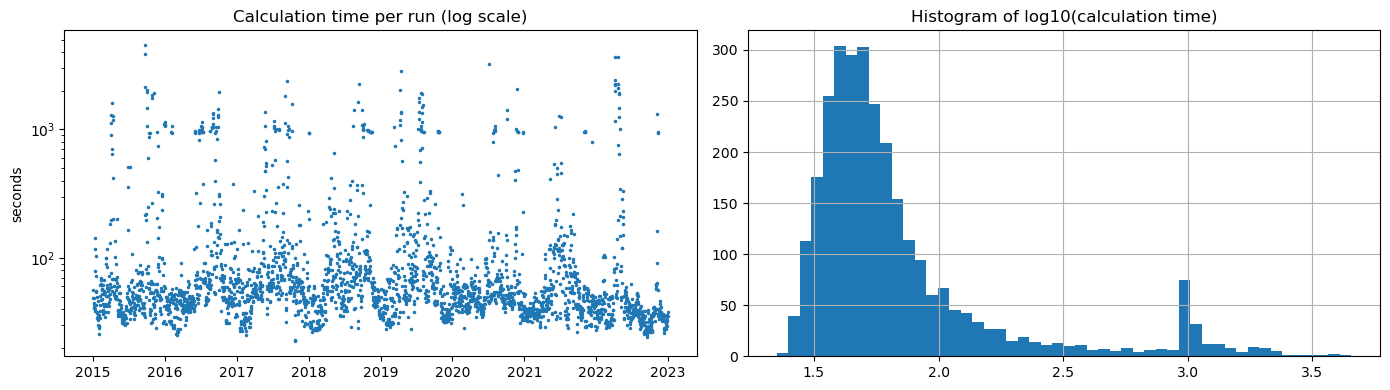

In [11]:
print(train["total_calculation_time"].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(train["starttime"], train["total_calculation_time"], ".", markersize=3)
axes[0].set_yscale("log")
axes[0].set_title("Calculation time per run (log scale)")
axes[0].set_ylabel("seconds")

train["total_calculation_time"].pipe(np.log10).hist(bins=50, ax=axes[1])
axes[1].set_title("Histogram of log10(calculation time)")
plt.tight_layout()
plt.show()

**Notes 2.2.3**
- Median ≈ 52 s, but a long tail up to ≈ 4500 s (over an hour).
- Slow runs come in clusters of consecutive start days, since cases overlap by 6/7 days. They recur in most years, with an extreme cluster in late 2022 (price crisis); 2020 is calm. A spike at ~1000 s suggests a solver time limit, so those labels may be suboptimal or noisy. Training data covers 2015–2022 and test probably covers 2023–2024, so we validate with a time-based split.

### 2.3 Is the data intuitive?

*Sanity checks against domain knowledge: volumes within [0, max_vol]? negative prices/inflows? generators on when price is high? any impossible combinations?*

#### 2.3.1 Are the values physically possible?

Volume within [0, max_vol], no negative inflow or water value, targets only 0/1, and how common negative prices are.

In [12]:
# Volume must be between 0 and the lake's max size (max_vol from the topology)
max_vol = pd.Series({name: r["max_vol"] for name, r in topology["model"]["reservoir"].items()})
lakes = volume.columns.drop("date")

vol_check = pd.DataFrame({
    "min": volume[lakes].min(),
    "max": volume[lakes].max(),
    "max_vol": max_vol[lakes],
})
vol_check["max as % of max_vol"] = (100 * vol_check["max"] / vol_check["max_vol"]).round(1)
vol_check["% of days above max_vol"] = (100 * (volume[lakes] > max_vol[lakes]).mean()).round(1)
display(vol_check)

print("Negative inflow values:     ", (inflow.drop(columns="date") < 0).sum().sum())
print("Negative water values:      ", (water_value.drop(columns="date") < 0).sum().sum())
print("Values in the target matrix:", np.unique(Y))

,min,max,max_vol,max as % of max_vol,% of days above max_vol
Kjelavatn,0.000,86.979,84.50,102.9,0.7
Staavatn,0.384,50.168,48.00,104.5,7.2
Langesae,13.701,78.616,78.00,100.8,5.3
Foersvatn,0.425,123.084,122.30,100.6,0.2
Venemo,8.703,21.806,23.00,94.8,0.0
Botnedalsvatn,0.397,55.778,54.17,103.0,5.5
Bitdalsvatn,14.874,111.825,110.00,101.7,2.2
Vaamarvatn,0.056,26.462,26.20,101.0,0.1
Langeidvatn,0.321,33.961,32.10,105.8,5.4
Totak,7.063,259.948,257.80,100.8,0.1


Negative inflow values:      0
Negative water values:       0
Values in the target matrix: [0 1]


In [13]:
# Negative prices and price level per year (price trimmed to < 2025: hourly part only)
p = price[price["date"] < "2025-01-01"]
col = "Day-ahead price (EUR/MWh)"
p.groupby(p["date"].dt.year)[col].agg(
    mean="mean", min="min", negative_hours=lambda s: (s < 0).sum()
).round(1)

,mean,min,negative_hours
date,,,
2015,19.8,1.0,0
2016,25.2,6.0,0
2017,28.8,3.0,0
2018,43.3,1.9,0
2019,39.3,5.9,0
2020,9.3,-1.7,5
2021,75.1,-2.0,5
2022,211.3,0.0,0
2023,79.4,-61.8,174


#### 2.3.2 Do the decisions make sense?

Expected from hydropower logic: more ON when the price is high, ON when price > water value, more ON in daytime, and few ON/OFF switches (start costs).

In [14]:
# Price for every hour of every train run: P[run, hour]
price_h = price[price["date"] < "2025-01-01"]
price_h = price_h.set_index(price_h["date"].dt.tz_convert(None))["Day-ahead price (EUR/MWh)"]

hours = train["starttime"].to_numpy()[:, None] + np.arange(168) * np.timedelta64(1, "h")
P = price_h.reindex(hours.ravel()).to_numpy().reshape(len(train), 168)

# Are generators ON more often in the expensive hours of the week?
# Rank each hour within its own run (0 = cheapest), so years with very different
# price levels (2020 vs 2022) can be compared.
rank = P.argsort(axis=1).argsort(axis=1)
band = pd.cut(rank.ravel(), bins=[-1, 41, 83, 125, 167],
              labels=["cheapest 25%", "25–50%", "50–75%", "most expensive 25%"])
on_share = Y.mean(axis=1).ravel()   # share of the 14 generators ON in each hour

pd.Series(on_share).groupby(band, observed=True).mean().round(3).rename("share ON")

cheapest 25%          0.416
25–50%                0.490
50–75%                0.542
most expensive 25%    0.617
Name: share ON, dtype: float64

In [15]:
# Core hydropower rule: run when price > water value.
# Each generator uses the water value of the lake it takes water from (upstream),
# at case start + 7 days (the end-of-week value SHOP uses). Mapping from docs/BRIEFING.md §2.2.
upstream = {
    "Hogga_G1": "Bandak",
    "Tokke_G1": "Vinjevatn", "Tokke_G2": "Vinjevatn", "Tokke_G3": "Vinjevatn", "Tokke_G4": "Vinjevatn",
    "Lio_G1": "Byrtevatn",
    "Byrte_G1": "Botnedalsvatn",
    "Vinje_G1": "Vaamarvatn", "Vinje_G2": "Vaamarvatn", "Vinje_G3": "Vaamarvatn",
    "Haukeli_G1": "Vatjern",
    "Songa_G1": "Songavatn",
    "Kjela_G1": "Foersvatn",
    "Vesle Kjela_G1": "Kjelavatn",
}

wv = water_value.set_index(water_value["date"].dt.tz_convert(None))
end_day = train["starttime"] + pd.Timedelta(days=7)

rows = []
for i, gen in enumerate(gen_names):
    w = wv[upstream[gen]].reindex(end_day).to_numpy()[:, None]   # one value per run
    above = P > w                                                # (runs, hours)
    rows.append({
        "generator": gen,
        "lake": upstream[gen],
        "ON % when price > wv": 100 * Y[:, i][above].mean(),
        "ON % when price < wv": 100 * Y[:, i][~above].mean(),
    })
pd.DataFrame(rows).round(1)

,generator,lake,ON % when price > wv,ON % when price < wv
0,Byrte_G1,Botnedalsvatn,97.5,6.3
1,Haukeli_G1,Vatjern,78.3,22.1
2,Hogga_G1,Bandak,95.4,26.5
3,Kjela_G1,Foersvatn,87.2,3.6
4,Lio_G1,Byrtevatn,99.3,45.7
5,Songa_G1,Songavatn,93.7,4.3
6,Tokke_G1,Vinjevatn,94.9,38.1
7,Tokke_G2,Vinjevatn,80.3,13.9
8,Tokke_G3,Vinjevatn,88.5,22.9
9,Tokke_G4,Vinjevatn,81.7,16.6


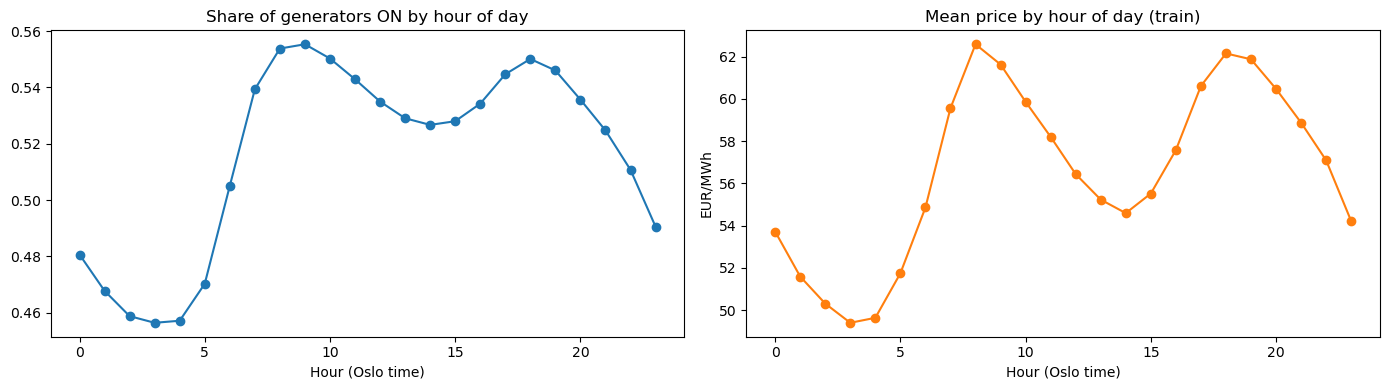

In [16]:
# More generators ON during the day than at night? (Norwegian local time)
local_hour = (pd.DatetimeIndex(hours.ravel()).tz_localize("UTC")
              .tz_convert("Europe/Oslo").hour.to_numpy())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.Series(on_share).groupby(local_hour).mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Share of generators ON by hour of day")
axes[0].set_xlabel("Hour (Oslo time)")

pd.Series(P.ravel()).groupby(local_hour).mean().plot(ax=axes[1], marker="o", color="tab:orange")
axes[1].set_title("Mean price by hour of day (train)")
axes[1].set_xlabel("Hour (Oslo time)")
axes[1].set_ylabel("EUR/MWh")

plt.tight_layout()
plt.show()

In [17]:
# Starting a generator costs money, so decisions should not flip back and forth every hour
switch = Y[:, :, 1:] != Y[:, :, :-1]
print(f"Share of hours where a generator switches ON<->OFF: {switch.mean():.3f}")
print(f"Share of (run, generator) with no switch in the whole week: {(switch.sum(axis=2) == 0).mean():.3f}")

Share of hours where a generator switches ON<->OFF: 0.012
Share of (run, generator) with no switch in the whole week: 0.588


#### 2.3.3 Do the files fit together?

In [18]:
vol_lakes = set(volume.columns.drop("date"))
wv_lakes = set(water_value.columns.drop("date"))
topo_lakes = set(topology["model"]["reservoir"])

print("Same lakes in volume and water value:", vol_lakes == wv_lakes)
print("Same lakes in volume and topology:   ", vol_lakes == topo_lakes)
print("Duplicate price timestamps:", price["date"].duplicated().sum())
print("Missing price hours in train runs:", np.isnan(P).sum())

Same lakes in volume and water value: True
Same lakes in volume and topology:    True
Duplicate price timestamps: 0
Missing price hours in train runs: 0


**Notes 2.3**

*A. Physical limits*
- No negative inflow or water values, and the targets are only 0/1 → OK.
- Volume goes **above `max_vol`** in 14 of 17 lakes, by up to 18% (Bandak). It's rare (0–7% of days) and mostly in autumn and early summer (floods). `max_vol` is the volume at the highest *regulated* level, so a lake can briefly go above it during a flood. Real, not an error → keep it, don't clip.
- Hyljelihyl and Vatjern have a constant volume (0.13 / 0.15) → constant features, drop in 5.2.
- Negative prices: 10 hours in all of train (2020–21) vs **380 hours in test** (174 in 2023, 206 in 2024). The price level also changes a lot (2020: 9, 2022: 211 EUR/MWh). Test is a different price regime → use relative price features, not raw EUR.

*B. Do the decisions make sense?*
- **Expensive hours → more ON:** in the most expensive 25% of hours in a week, 62% of generators are ON, vs 42% in the cheapest 25%.
- **Price > water value → ON:** this works very well. For most generators the ON rate is 80–99% when price > upstream water value (at +7 days) and 4–38% when it's below. Weakest for Vinje (G3: 42% vs 7%), which runs less often in general.
- **Day vs night:** ON share is highest at 08–10 and 18–19 (Oslo time) and lowest at 02–04. This matches the price pattern (morning and evening peaks).
- **Decisions are "sticky":** only 1.2% of hours switch ON↔OFF, and in 59% of runs a generator never switches during the whole week. This fits with the start costs.

*C. Do the files fit together?*
- The same 17 lakes appear in volume, water value and topology, and the same 14 generators appear in the targets and topology (1.3).
- No duplicate price timestamps, and the price matrix for all train runs has no missing hours.

**Conclusion:** the data is physically sensible, and the decisions follow hydropower logic. The two things to handle are the different price regime in test and the few volumes above `max_vol`.

## 3. Exploring individual features

*Lecture tools: `describe()`, histograms, index-vs-value plots, `value_counts()`, `isnull()`.*

### 3.1 Target (unit commitment)

#### 3.1.1 On-rate per generator (class balance)

*`value_counts()` / mean per generator.*

Overall share ON (all generators, all hours): 0.516


,Vinje_G3,Vinje_G2,Vesle Kjela_G1,Kjela_G1,Tokke_G2,Vinje_G1,Songa_G1,Tokke_G4,Byrte_G1,Haukeli_G1,Tokke_G3,Hogga_G1,Tokke_G1,Lio_G1
share ON,0.259,0.42,0.467,0.471,0.478,0.485,0.485,0.498,0.542,0.547,0.564,0.595,0.671,0.747


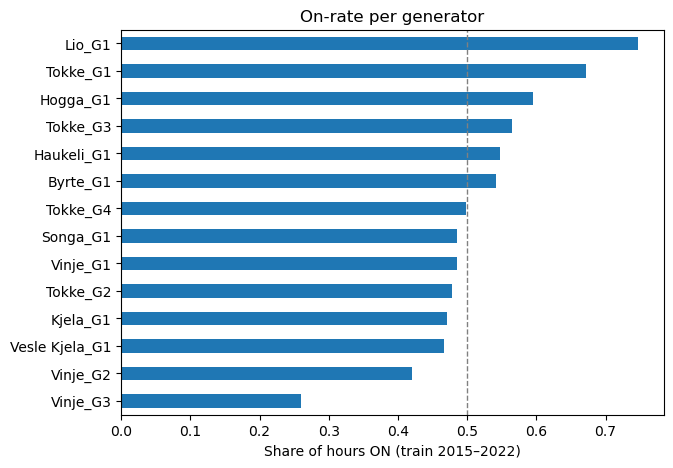

In [28]:
# Statistics: share of hours ON per generator (= class balance)
on_rate = pd.Series(Y.mean(axis=(0, 2)), index=gen_names).sort_values()
print(f"Overall share ON (all generators, all hours): {Y.mean():.3f}")
display(on_rate.round(3).to_frame("share ON").T)

# Plot
ax = on_rate.plot.barh(figsize=(7, 5))
ax.axvline(0.5, color="grey", ls="--", lw=1)
ax.set_xlabel("Share of hours ON (train 2015–2022)")
ax.set_title("On-rate per generator")
plt.show()

**Notes 3.1.1**
- Overall share ON = **0.516** → the classes are balanced overall.
- Per generator it ranges from **0.26 (Vinje G3)** to **0.75 (Lio G1)**. No generator is almost always ON or OFF, so every unit has both classes.
- Within a plant there is a clear order: Vinje G1 (0.49) > G2 (0.42) > G3 (0.26) and Tokke G1 (0.67) > G3 (0.56) > G4 (0.50) > G2 (0.48). The units are identical (3.7), so this looks like a fixed priority: G1 is used first.

#### 3.1.2 On-rate over the 168-hour horizon (t0–t167)

*Daily/weekly pattern within the plan.*

Share ON in t0–t3: 0.451   rest of the plan: 0.518
Lowest: t1 (0.448)   highest: t55 (0.557)


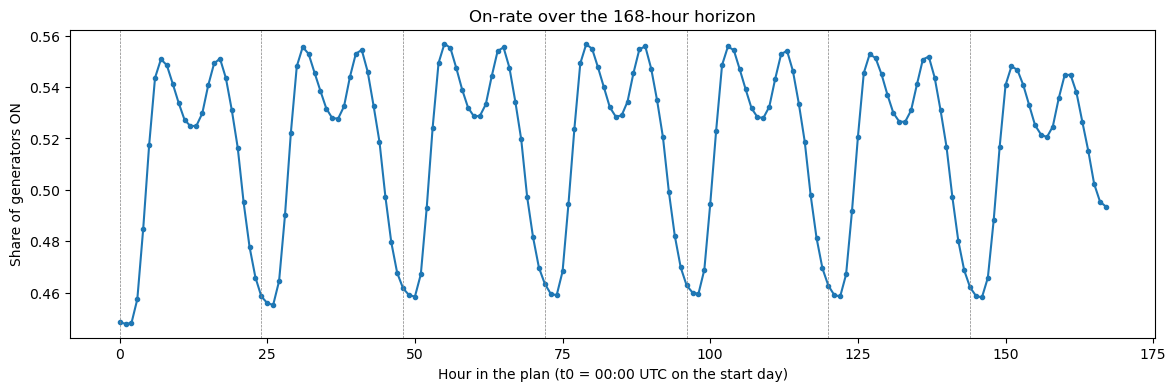

In [29]:
# Statistics: share ON for each hour of the plan (averaged over all runs and generators)
on_by_t = Y.mean(axis=(0, 1))
print(f"Share ON in t0–t3: {on_by_t[:4].mean():.3f}   rest of the plan: {on_by_t[4:].mean():.3f}")
print(f"Lowest: t{on_by_t.argmin()} ({on_by_t.min():.3f})   highest: t{on_by_t.argmax()} ({on_by_t.max():.3f})")

# Plot
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(on_by_t, marker=".")
for day in range(0, 168, 24):
    ax.axvline(day, color="grey", ls="--", lw=0.5)   # start of each day (00:00 UTC)
ax.set_xlabel("Hour in the plan (t0 = 00:00 UTC on the start day)")
ax.set_ylabel("Share of generators ON")
ax.set_title("On-rate over the 168-hour horizon")
plt.show()

**Notes 3.1.2**
- The share ON follows a **daily cycle**: lowest at night (t0–t3 ≈ 0.45, i.e. 01–04 Oslo time), highest in the morning (max t55 = 0.557).
- The low start (t0–t3) is mainly the night dip, not a start effect: the same night hours on day 2 (t24) are also low (≈ 0.46).
- Apart from the daily cycle, there is no clear trend from the start to the end of the 168 hours.

#### 3.1.3 Seasonal / yearly patterns

*On-rate per month and per year.*

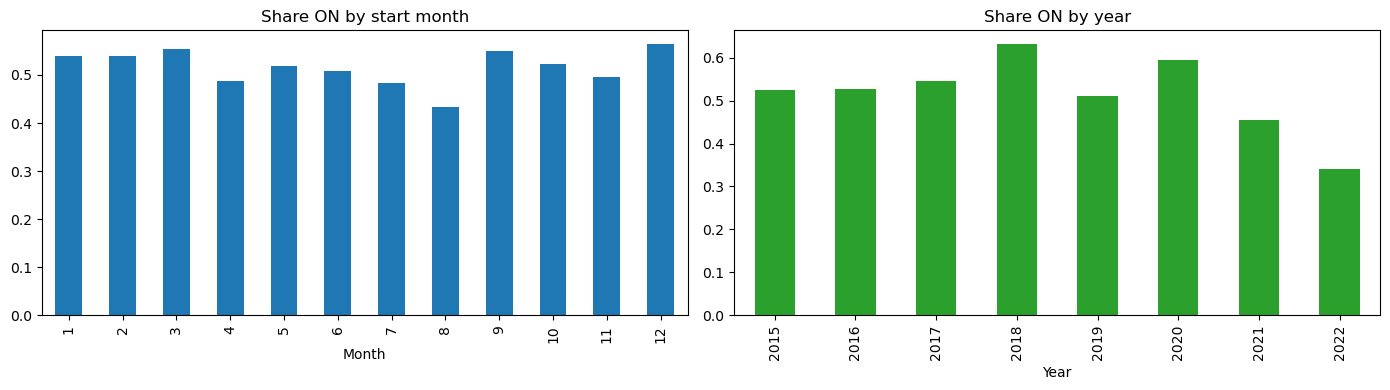

In [30]:
year = train["starttime"].dt.year
month = train["starttime"].dt.month
run_on = Y.mean(axis=(1, 2))   # share ON in each run (all generators, all hours)

# Statistics + plots: share ON per month and per year
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.Series(run_on).groupby(month).mean().plot.bar(ax=axes[0])
axes[0].set_title("Share ON by start month")
axes[0].set_xlabel("Month")
pd.Series(run_on).groupby(year).mean().plot.bar(ax=axes[1], color="tab:green")
axes[1].set_title("Share ON by year")
axes[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

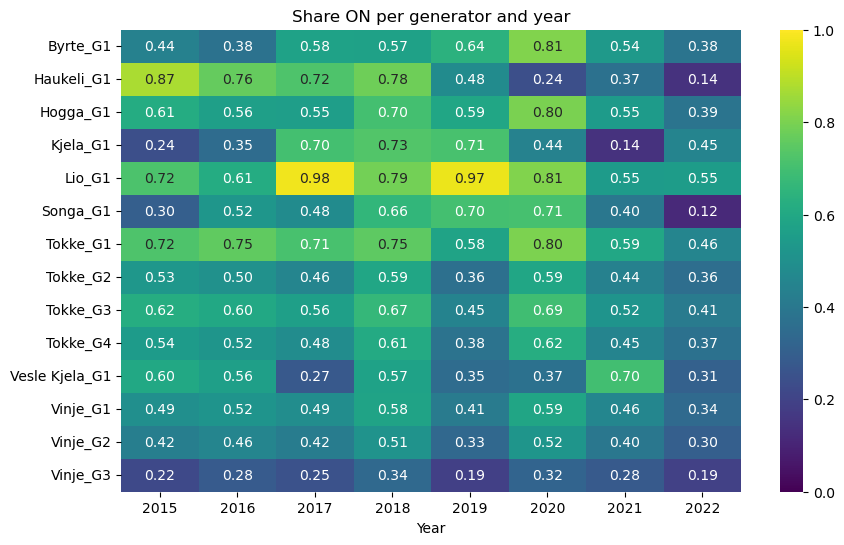

In [31]:
# Share ON per generator per year: does each generator's behaviour change between years?
gen_year = pd.DataFrame(Y.mean(axis=2), columns=gen_names).groupby(year).mean()

plt.figure(figsize=(10, 6))
sns.heatmap(gen_year.T, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Share ON per generator and year")
plt.xlabel("Year")
plt.show()

**Notes 3.1.3**
- **By month:** small differences, from 0.43 (August) to 0.57 (December).
- **By year:** big differences, from **0.63 in 2018** to **0.34 in 2022**. 2022 had the price crisis and low reservoirs (3.4).
- **Per generator per year** (heatmap): behaviour changes a lot between years, e.g. Haukeli 0.87 (2015) → 0.14 (2022), Kjela 0.24 → 0.73 → 0.14, Songa 0.71 (2020) → 0.12 (2022).
- → A model can't just learn "generator X is usually ON". It has to learn *why* from price, water value and reservoirs. This is also why validation is done per year.

### 3.2 Day-ahead price

*`describe()`, histogram, price over time (index vs value), daily/weekly profile.*

,train 2015–22,test 2023–24
count,70128.0,17544.0
mean,56.5,64.8
std,77.9,38.2
min,-2.0,-61.8
25%,22.9,41.9
50%,31.7,59.3
75%,50.0,85.9
max,844.0,898.2


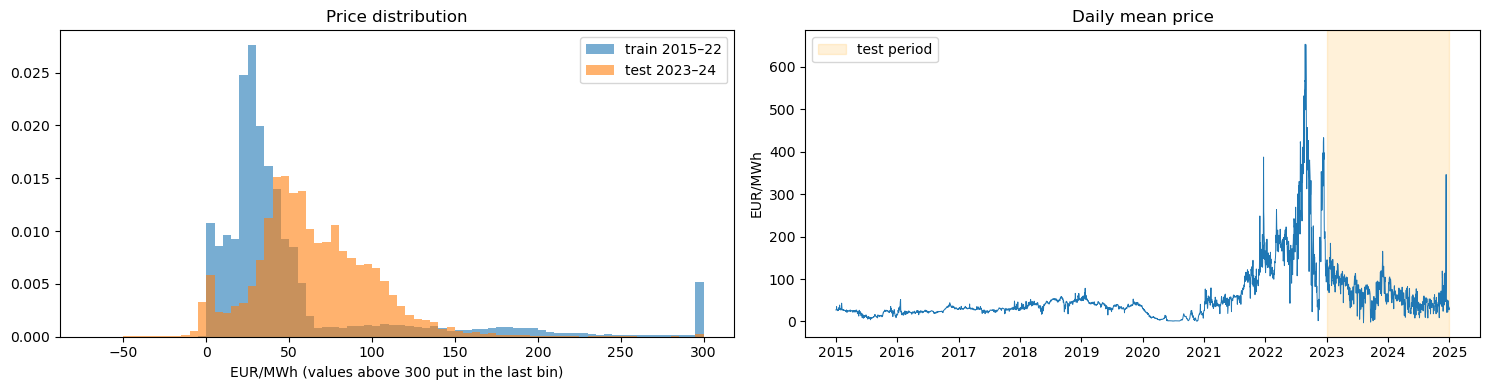

In [32]:
col = "Day-ahead price (EUR/MWh)"
price_s = price[price["date"] < "2025-01-01"].set_index("date")[col]   # hourly part only
is_test = price_s.index.year >= 2023

# Statistics: train vs test period
display(pd.DataFrame({
    "train 2015–22": price_s[~is_test].describe(),
    "test 2023–24": price_s[is_test].describe(),
}).round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Histogram (cut at 300 EUR/MWh so the bulk is visible; only the 2022 crisis goes higher)
bins = np.arange(-70, 305, 5)
axes[0].hist(price_s[~is_test].clip(upper=300), bins=bins, alpha=0.6, density=True, label="train 2015–22")
axes[0].hist(price_s[is_test].clip(upper=300), bins=bins, alpha=0.6, density=True, label="test 2023–24")
axes[0].set_xlabel("EUR/MWh (values above 300 put in the last bin)")
axes[0].set_title("Price distribution")
axes[0].legend()

# Plot over time (daily mean)
daily_price = price_s.resample("D").mean()
axes[1].plot(daily_price.index, daily_price, lw=0.7)
axes[1].axvspan(pd.Timestamp("2023-01-01", tz="UTC"), daily_price.index[-1], color="orange", alpha=0.15, label="test period")
axes[1].set_ylabel("EUR/MWh")
axes[1].set_title("Daily mean price")
axes[1].legend()

plt.tight_layout()
plt.show()

**Notes 3.2**
- The distribution is **right-skewed**: most hours are cheap, with a long tail of very expensive hours.
- **Train:** median 31.7 EUR/MWh, but a huge spread (std 78) because of the 2022 crisis (monthly mean up to ≈ 440 in August 2022, max 844).
- **Test:** median **59.3**, i.e. higher than a typical train year but without the extreme 2022 level (std 38). It has **negative prices down to −62**, which almost never happen in train (min −2). The highest price of all (898) is in test (2024-12-12).
- → The test price level and shape differ from train → use **relative price features** (compared with the week's mean / the water value), not raw EUR.

### 3.3 Inflow

*Seasonal profile (snowmelt), long history 1958–2025 vs. 2015–2024.*

,mean,50%,max
Songavatn,23.87,10.63,305.64
Bandak,17.51,7.33,636.81
Vinjevatn,13.35,6.37,206.36
Totak,9.74,4.65,150.59
Botnedalsvatn,6.52,2.40,473.03
r_Vest_Vassdraget,6.45,2.38,468.04
Staavatn,6.23,1.84,102.43
Bordalsvatn,5.73,2.11,415.76
Bitdalsvatn,5.18,2.31,66.37
Byrtevatn,4.84,1.78,351.29


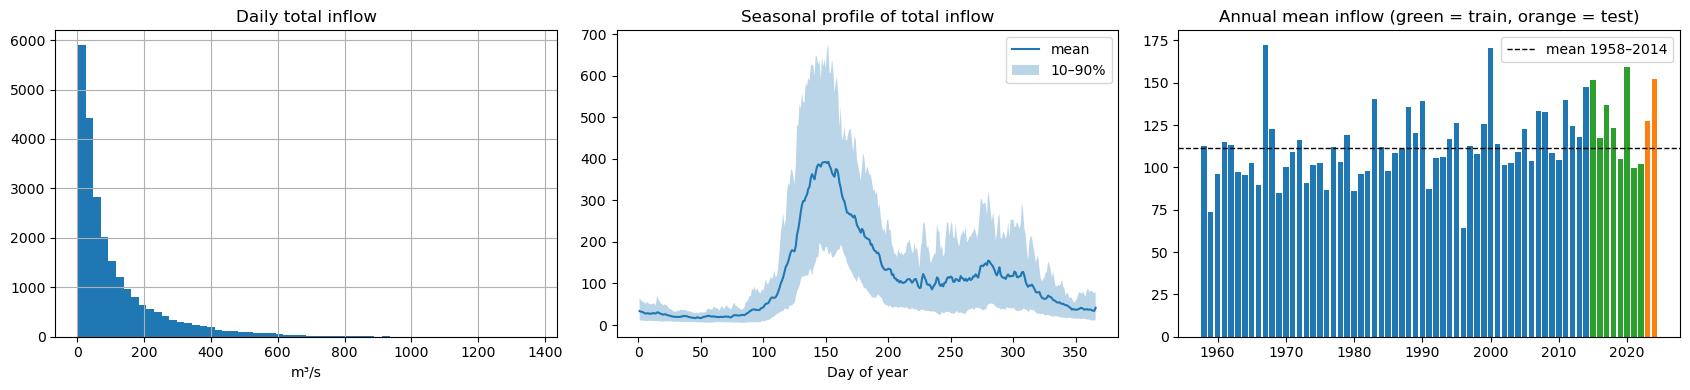

Annual mean inflow 2015–2024: {2015: 152.0, 2016: 117.0, 2017: 137.0, 2018: 123.0, 2019: 105.0, 2020: 159.0, 2021: 100.0, 2022: 102.0, 2023: 128.0, 2024: 152.0}


In [33]:
inflow_s = inflow.set_index("date")
# Total inflow to the whole system, daily mean (m³/s), full years only
inflow_total = inflow_s.sum(axis=1).resample("D").mean()[:"2024"]

# Statistics per reservoir
display(inflow_s.describe().T[["mean", "50%", "max"]].sort_values("mean", ascending=False).round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# Histogram
inflow_total.hist(bins=60, ax=axes[0])
axes[0].set_xlabel("m³/s")
axes[0].set_title("Daily total inflow")

# Plot: seasonal profile (mean and 10–90% band over 1958–2024)
by_doy = inflow_total.groupby(inflow_total.index.dayofyear)
axes[1].plot(by_doy.mean(), label="mean")
axes[1].fill_between(by_doy.mean().index, by_doy.quantile(0.1), by_doy.quantile(0.9), alpha=0.3, label="10–90%")
axes[1].set_xlabel("Day of year")
axes[1].set_title("Seasonal profile of total inflow")
axes[1].legend()

# Plot: wet and dry years
annual = inflow_total.groupby(inflow_total.index.year).mean()
colors = ["tab:blue" if y < 2015 else "tab:green" if y < 2023 else "tab:orange" for y in annual.index]
axes[2].bar(annual.index, annual, color=colors)
axes[2].axhline(annual.loc[:2014].mean(), color="black", ls="--", lw=1, label="mean 1958–2014")
axes[2].set_title("Annual mean inflow (green = train, orange = test)")
axes[2].legend()

plt.tight_layout()
plt.show()

print("Annual mean inflow 2015–2024:", annual.loc[2015:].round(0).to_dict())

**Notes 3.3**
- **Snowmelt dominates:** total inflow is ≈ 20–27 m³/s in Jan–Mar and ≈ 300 m³/s in May–June (≈ 15× more). The peak is around day 152 (1 June).
- The histogram is very right-skewed (a few huge flood days).
- **Wet and dry years:** the long-term mean is 111 m³/s (1958–2014). Train has wet years (2015: 152, 2020: 159) and dry years (2019: 105, 2021: 100, 2022: 102). Test: 2023 normal (128), 2024 wet (152).
- The biggest inflows go to Songavatn, Bandak and Vinjevatn. Inflow is much more variable than the mean suggests (max ≫ median).

### 3.4 Reservoir volume

*Level over time, compare with `max_vol` from topology.*

,Songavatn,Totak,Bordalsvatn,Bandak,Vinjevatn
count,3654.00,3654.00,3654.00,3654.00,3654.00
mean,0.66,0.65,0.72,0.76,0.68
std,0.23,0.28,0.23,0.05,0.12
min,0.08,0.03,0.01,0.60,0.16
25%,0.50,0.43,0.61,0.73,0.61
50%,0.68,0.80,0.80,0.76,0.70
75%,0.88,0.88,0.90,0.78,0.78
max,1.01,1.01,1.02,1.18,1.12


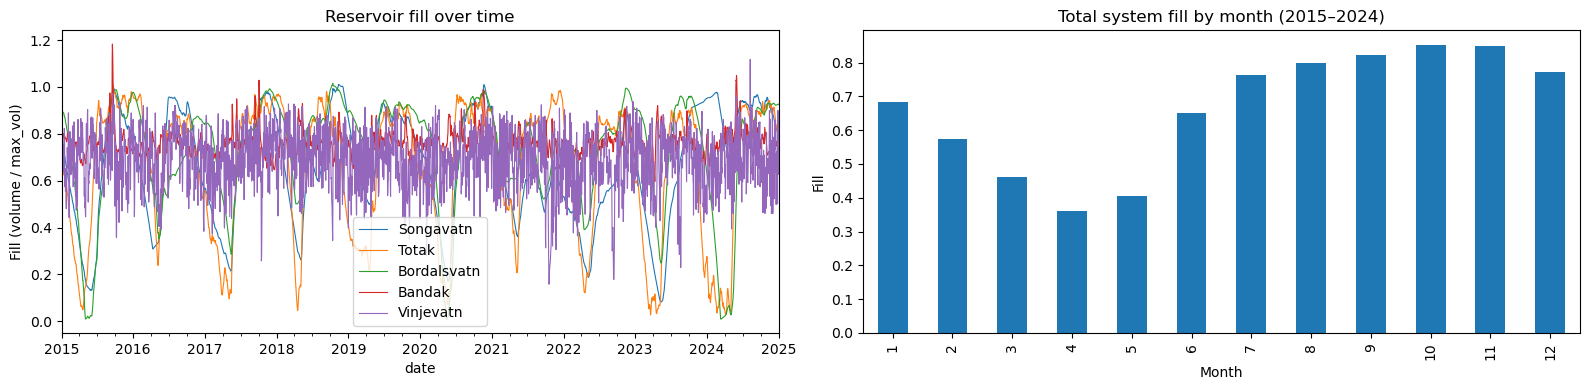

Mean total fill per year: {2015: 0.63, 2016: 0.69, 2017: 0.66, 2018: 0.72, 2019: 0.72, 2020: 0.68, 2021: 0.64, 2022: 0.58, 2023: 0.61, 2024: 0.73, 2025: 0.78}


In [34]:
vol_s = volume.set_index("date")
fill = vol_s / max_vol[vol_s.columns]           # share of the lake's size (1 = full)
total_fill = vol_s.sum(axis=1) / max_vol[vol_s.columns].sum()
big_lakes = ["Songavatn", "Totak", "Bordalsvatn", "Bandak", "Vinjevatn"]

# Statistics
display(fill[big_lakes].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 4))

# Plot over time
fill[big_lakes].plot(ax=axes[0], lw=0.8)
axes[0].set_ylabel("Fill (volume / max_vol)")
axes[0].set_title("Reservoir fill over time")

# Plot: seasonal profile of the whole system
total_fill.groupby(total_fill.index.month).mean().plot.bar(ax=axes[1])
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Fill")
axes[1].set_title("Total system fill by month (2015–2024)")

plt.tight_layout()
plt.show()

print("Mean total fill per year:", total_fill.groupby(total_fill.index.year).mean().round(2).to_dict())

**Notes 3.4**
- **Seasonal cycle:** the whole system is emptiest in **April (≈ 36% full)** before the snowmelt and fullest in **Oct–Nov (≈ 85%)**.
- The big storage lakes (Songavatn, Totak, Bordalsvatn) swing between almost empty and full. **Bandak** stays at 73–79% (std 0.05), and **Vinjevatn** is small (9.4 Mm³), so these work more like buffers.
- **2022 had the lowest fill (58% on average)**, which fits with few generators ON that year (3.1.3).
- (2025 in the yearly print is only 1 day of data.)

### 3.5 Water value

*Over time per reservoir, compare with price level.*

Distinct water value series: 9 of 17 columns (the rest are exact copies)


,Vinjevatn,Songavatn,Bandak
count,3654.0,3654.0,3654.0
mean,61.5,74.9,63.3
std,101.5,132.1,89.9
min,0.0,0.0,0.0
25%,11.8,9.7,16.1
50%,33.0,30.4,36.1
75%,63.8,62.5,67.7
max,1135.0,1202.6,780.0


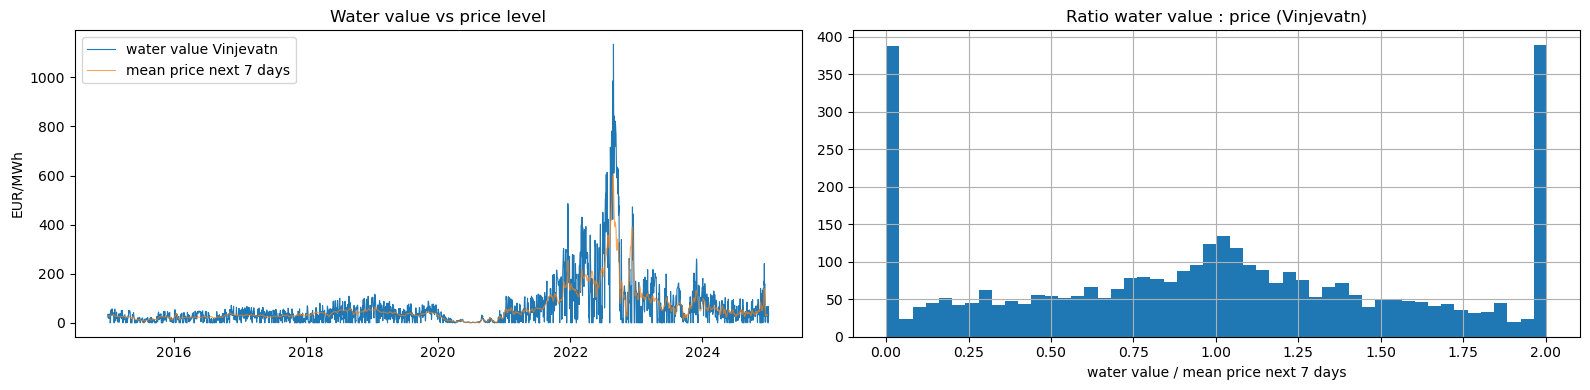

Correlation water value vs next-week mean price: 0.836
Ratio quantiles: {0.01: 0.0, 0.5: 1.0, 0.99: 2.0}


In [35]:
wv_s = water_value.set_index("date")

# Statistics
n_distinct = wv_s.T.drop_duplicates().shape[0]
print(f"Distinct water value series: {n_distinct} of {wv_s.shape[1]} columns (the rest are exact copies)")
display(wv_s[["Vinjevatn", "Songavatn", "Bandak"]].describe().round(1))

# Water value vs the mean price of the following 7 days
next_week_price = daily_price.rolling(7).mean().shift(-6).reindex(wv_s.index)
ratio = wv_s["Vinjevatn"] / next_week_price

fig, axes = plt.subplots(1, 2, figsize=(16, 4))

# Plot over time
axes[0].plot(wv_s.index, wv_s["Vinjevatn"], lw=0.8, label="water value Vinjevatn")
axes[0].plot(next_week_price.index, next_week_price, lw=0.8, alpha=0.7, label="mean price next 7 days")
axes[0].set_ylabel("EUR/MWh")
axes[0].set_title("Water value vs price level")
axes[0].legend()

# Histogram of the ratio
ratio[next_week_price > 1].hist(bins=50, ax=axes[1])
axes[1].set_xlabel("water value / mean price next 7 days")
axes[1].set_title("Ratio water value : price (Vinjevatn)")

plt.tight_layout()
plt.show()

print("Correlation water value vs next-week mean price:", round(wv_s["Vinjevatn"].corr(next_week_price), 3))
print("Ratio quantiles:", ratio[next_week_price > 1].quantile([0.01, 0.5, 0.99]).round(2).to_dict())

**Notes 3.5**
- Only **9 distinct series** in 17 columns: several lakes share exactly the same water value → deduplicate (5.3).
- The water value **follows the price level** closely (correlation 0.84 with the mean price of the next 7 days) and peaks in 2022.
- The ratio water value / next week's mean price lies between **0 and 2** (median 1.0). So the water value ≈ c × next week's mean price, where c (0–2) says how scarce the water is (2 = little water, 0 = full lake).
- → The water value contains the price level, so the useful information is **price compared with water value**, which matches the rule found in 2.3.2.

### 3.6 Constraints (min flow, min volume)

*When are they active (non-zero)?*

,share of hours active,distinct values,min,max
b_Kjelavatn,1.000,31,0.3,0.75
b_Hyljelihyl,1.000,31,0.5,2.00
b_Vinjevatn,1.000,2,1.0,2.00
b_Byrtevatn,0.339,2,0.0,0.20
b_Bandak,1.000,2,4.0,5.00
r_Vest_Vassdraget,1.000,3,5.0,14.00


,share of hours active,values when active,months active
Totak,0.339,"[194.233, 211.89]","[7, 8, 9, 10, 11]"
Byrtevatn,0.126,[67.677],"[7, 8]"
Staavatn,0.255,[46.656],"[7, 8, 9, 10]"


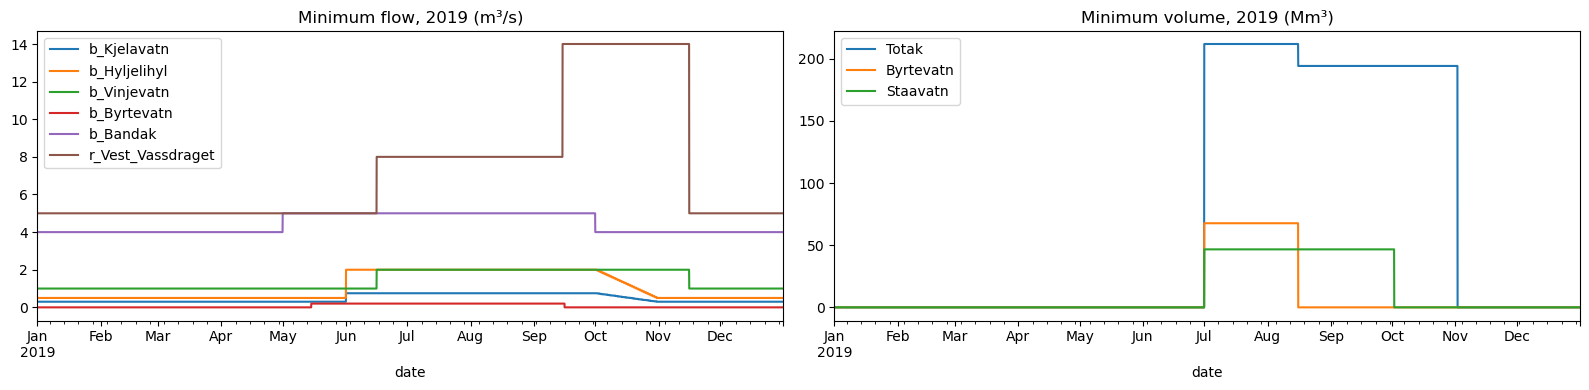

In [36]:
mf = min_flow.set_index("date")
mvl = min_volume.set_index("date")

# Statistics: how often is each constraint active (> 0), and which values does it take?
display(pd.DataFrame({
    "share of hours active": (mf > 0).mean(),
    "distinct values": mf.nunique(),
    "min": mf.min(), "max": mf.max(),
}).round(3))
display(pd.DataFrame({
    "share of hours active": (mvl > 0).mean().round(3),
    "values when active": [sorted(mvl.loc[mvl[c] > 0, c].unique()) for c in mvl],
    "months active": [sorted(mvl.index[mvl[c] > 0].month.unique()) for c in mvl],
}, index=mvl.columns))

# Plot: one example year
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
mf.loc["2019"].plot(ax=axes[0])
axes[0].set_title("Minimum flow, 2019 (m³/s)")
mvl.loc["2019"].plot(ax=axes[1])
axes[1].set_title("Minimum volume, 2019 (Mm³)")
plt.tight_layout()
plt.show()

**Notes 3.6**
- **Minimum flow** is active almost all the time for 5 of 6 rivers, at a low winter level that **steps up from June** (e.g. b_Kjelavatn 0.3 → 0.75 m³/s in Jun–Sep; r_Vest_Vassdraget 5 → 8 in summer and 14 in October). b_Byrtevatn is only active in May–Sep.
- **Minimum volume** is only active in **summer and autumn**: Totak Jul–Nov (34% of hours), Staavatn Jul–Oct (26%), Byrtevatn Jul–Aug (13%). It takes the same one or two values every year.
- → The constraints follow a fixed **seasonal calendar**, so their information is mostly the same as "time of year". Min volume in Totak may matter, because it forces the lake to stay high (→ less water for Vinje).

### 3.7 Topology

*Reservoir → plant → generator mapping, p_min/p_max, start costs.*

In [37]:
# Statistics: one row per generator, from the topology YAML
# (+ upstream lake from 2.3.2 and on-rate from 3.1.1)
gen_table = pd.DataFrame({
    name: {
        "takes water from": upstream[name],
        "p_min (MW)": g["p_min"],
        "p_max (MW)": g["p_max"],
        "start cost": g["startcost_const"],
    }
    for name, g in topology["model"]["generator"].items()
}).T
gen_table["share ON"] = on_rate.round(2)
gen_table

,takes water from,p_min (MW),p_max (MW),start cost,share ON
Hogga_G1,Bandak,3,17,94,0.59
Tokke_G1,Vinjevatn,36.9,107.5,214,0.67
Tokke_G2,Vinjevatn,36.9,107.5,214,0.48
Tokke_G3,Vinjevatn,36.9,107.5,214,0.56
Tokke_G4,Vinjevatn,36.9,107.5,214,0.50
Lio_G1,Byrtevatn,14.8,43,163,0.75
Byrte_G1,Botnedalsvatn,6.9,20,135,0.54
Vinje_G1,Vaamarvatn,34.4,100,198,0.49
Vinje_G2,Vaamarvatn,34.4,100,198,0.42
Vinje_G3,Vaamarvatn,34.4,100,198,0.26


**Notes 3.7**
- **Tokke has 4 identical units** and **Vinje has 3 identical units** (same p_min, p_max and start cost), yet their ON rates differ a lot → a fixed priority order inside each plant (3.1.1).
- The biggest units are Songa (120 MW), Tokke (107.5 MW) and Vinje (100 MW). The smallest is Haukeli (4.9 MW).
- For most units p_min ≈ 34% of p_max: if a unit is ON, it must produce at least about a third of its maximum. Exceptions: Hogga (18%) and Haukeli (6%).
- Start costs range from 92 (Vesle Kjela) to 222 (Songa). Expensive starts → long ON/OFF stretches (2.3.2).
- See `data/extended/Tokke_topology.pdf` for the diagram of the cascade.

## 4. Exploring pairs and groups of features

*Lecture tools: scatter plots (coloured by class / train vs test), scatter matrix, correlation matrix, sorted feature statistics.*

### 4.1 Price vs. commitment

*On-rate as a function of price.*

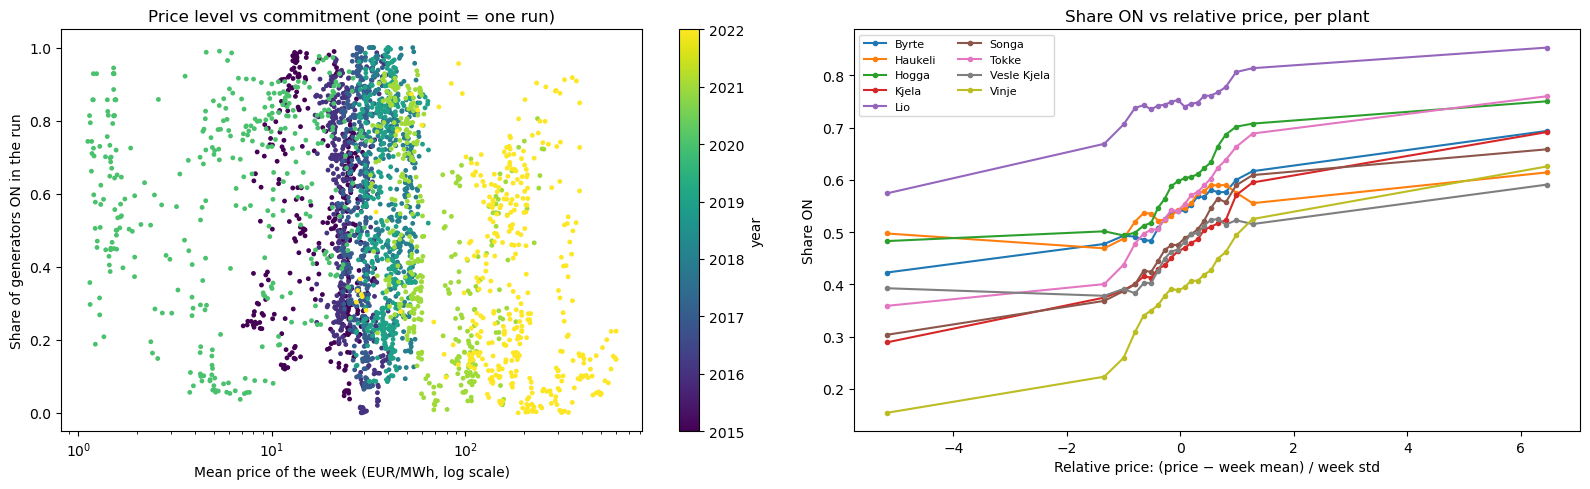

Correlation (week mean price vs share ON per run): -0.271


In [38]:
# Scatter plot: one point per run. Mean price of the week vs share of generators ON
week_price = P.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sc = axes[0].scatter(week_price.clip(min=1), run_on, c=year, cmap="viridis", s=6)
axes[0].set_xscale("log")
axes[0].set_xlabel("Mean price of the week (EUR/MWh, log scale)")
axes[0].set_ylabel("Share of generators ON in the run")
axes[0].set_title("Price level vs commitment (one point = one run)")
plt.colorbar(sc, ax=axes[0], label="year")

# Statistics plot: share ON vs *relative* price (how expensive the hour is within its own week)
rel_price = (P - P.mean(axis=1, keepdims=True)) / P.std(axis=1, keepdims=True)
rel_bin = pd.qcut(rel_price.ravel(), 20)
plants = sorted({g.rsplit("_G", 1)[0] for g in gen_names})
for plant in plants:
    idx = [i for i, g in enumerate(gen_names) if g.startswith(plant + "_G")]
    on_plant = Y[:, idx, :].mean(axis=1).ravel()
    curve = pd.Series(on_plant).groupby(rel_bin, observed=True).mean()
    axes[1].plot([b.mid for b in curve.index], curve.values, marker=".", label=plant)
axes[1].set_xlabel("Relative price: (price − week mean) / week std")
axes[1].set_ylabel("Share ON")
axes[1].set_title("Share ON vs relative price, per plant")
axes[1].legend(fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

print("Correlation (week mean price vs share ON per run):", round(np.corrcoef(week_price, run_on)[0, 1], 3))

**Notes 4.1**
- **Raw price level does *not* explain commitment.** In the scatter plot, the runs form a cloud per year, and the correlation between a week's mean price and its share ON is even negative (−0.27). 2022 had the highest prices but few generators ON.
- **Relative price does.** Within a week, the more expensive the hour, the higher the share ON, for every plant. The effect is strongest for Vinje (0.15 → 0.63) and Tokke. Lio is ON most of the time anyway.
- → Price only matters *compared with something*: the week's own level, or the water value (4.2).

### 4.2 Price vs. water value, coloured by on/off

*Expected key plot: price − water value as decision rule.*

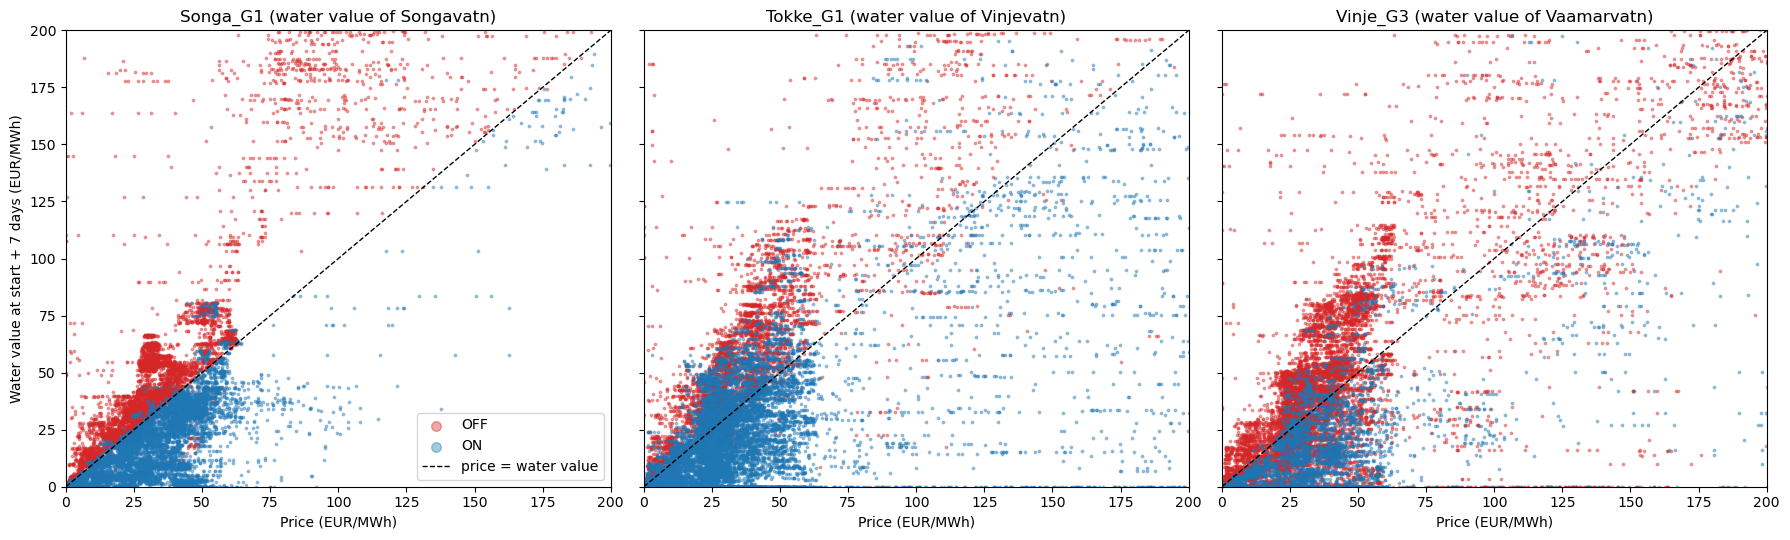

In [39]:
# Scatter plot coloured by class: price vs the generator's upstream water value (+7 days)
rng = np.random.default_rng(0)
sample = rng.choice(P.size, 20000, replace=False)   # subsample hours so the plot is readable

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)
for ax, gen in zip(axes, ["Songa_G1", "Tokke_G1", "Vinje_G3"]):
    i = gen_names.index(gen)
    w = wv[upstream[gen]].reindex(end_day).to_numpy()[:, None] * np.ones((1, 168))   # same value for all 168 hours
    x, y_, on = P.ravel()[sample], w.ravel()[sample], Y[:, i, :].ravel()[sample]
    ax.scatter(x[on == 0], y_[on == 0], s=3, alpha=0.4, color="tab:red", label="OFF")
    ax.scatter(x[on == 1], y_[on == 1], s=3, alpha=0.4, color="tab:blue", label="ON")
    ax.plot([0, 200], [0, 200], "k--", lw=1, label="price = water value")
    ax.set_xlim(0, 200)
    ax.set_ylim(0, 200)
    ax.set_xlabel("Price (EUR/MWh)")
    ax.set_title(f"{gen} (water value of {upstream[gen]})")
axes[0].set_ylabel("Water value at start + 7 days (EUR/MWh)")
axes[0].legend(markerscale=4)
plt.tight_layout()
plt.show()

In [40]:
# How well does the single number (price − water value) separate ON from OFF? -> ROC-AUC per generator
def auc(y_true, score):
    """ROC-AUC via the rank formula (same as sklearn's roc_auc_score)."""
    ranks = pd.Series(score).rank().to_numpy()
    n_on = y_true.sum()
    n_off = len(y_true) - n_on
    return (ranks[y_true == 1].sum() - n_on * (n_on + 1) / 2) / (n_on * n_off)

rows = []
for i, gen in enumerate(gen_names):
    w = wv[upstream[gen]].reindex(end_day).to_numpy()[:, None]
    rows.append({
        "generator": gen,
        "AUC price − water value": auc(Y[:, i, :].ravel(), (P - w).ravel()),
        "AUC price only": auc(Y[:, i, :].ravel(), P.ravel()),
    })
auc_table = pd.DataFrame(rows).set_index("generator").sort_values("AUC price − water value").round(3)
auc_table

,AUC price − water value,AUC price only
generator,,
Vinje_G2,0.760,0.462
Vinje_G1,0.760,0.459
Vinje_G3,0.781,0.495
Haukeli_G1,0.853,0.394
Tokke_G4,0.894,0.434
Tokke_G1,0.897,0.391
Tokke_G2,0.901,0.437
Tokke_G3,0.903,0.423
Hogga_G1,0.904,0.421


**Notes 4.2**
- **This is the key plot.** Blue (ON) lies mainly below the diagonal (price > water value) and red (OFF) above it.
- Songa G1 is separated almost perfectly. Tokke G1 is a bit blurrier. Vinje G3 is often OFF even below the diagonal, because it's the last unit in line at Vinje (3.1.1).
- The horizontal stripes appear because each run has one water value (at start + 7 days) for all of its 168 hours.
- **AUC of the single number "price − water value": 0.76–0.99** (Byrte 0.99, Songa 0.97, Tokke ≈ 0.90, Vinje ≈ 0.76–0.78).
- **AUC of price alone: 0.39–0.56**, i.e. no better than guessing. Years with high prices also have high water values (3.5), so price alone says nothing.
- → **Price − upstream water value is the most important feature.** Vinje and Tokke need more information (unit order, coupling, reservoirs).

### 4.3 Reservoir volume / inflow vs. commitment

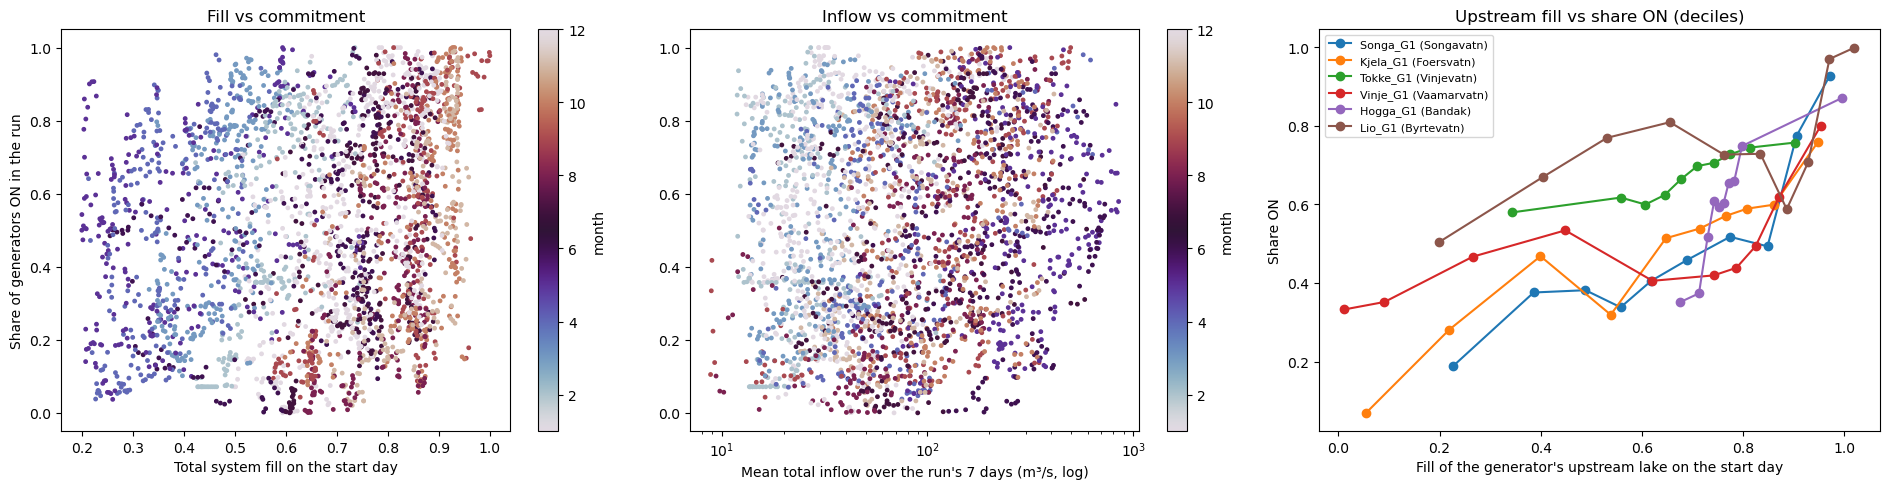

Correlation fill vs share ON:   0.241
Correlation inflow vs share ON: 0.169


In [41]:
start = train["starttime"]
naive = lambda s: s.set_axis(s.index.tz_convert(None))   # drop the UTC label so we can look up naive dates

start_fill = naive(total_fill).reindex(start).to_numpy()                 # system fill on the start day
week_inflow = naive(inflow_total).rolling(7).mean().shift(-6).reindex(start).to_numpy()   # mean inflow over the run's 7 days

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# Scatter: reservoir fill at start vs share ON, coloured by month
sc = axes[0].scatter(start_fill, run_on, c=month, cmap="twilight", s=6)
axes[0].set_xlabel("Total system fill on the start day")
axes[0].set_ylabel("Share of generators ON in the run")
axes[0].set_title("Fill vs commitment")
plt.colorbar(sc, ax=axes[0], label="month")

# Scatter: inflow during the week vs share ON
sc = axes[1].scatter(week_inflow, run_on, c=month, cmap="twilight", s=6)
axes[1].set_xscale("log")
axes[1].set_xlabel("Mean total inflow over the run's 7 days (m³/s, log)")
axes[1].set_title("Inflow vs commitment")
plt.colorbar(sc, ax=axes[1], label="month")

# Statistics plot: generator's own upstream lake fill (deciles) vs its share ON
for gen in ["Songa_G1", "Kjela_G1", "Tokke_G1", "Vinje_G1", "Hogga_G1", "Lio_G1"]:
    i = gen_names.index(gen)
    lake_fill = naive(fill[upstream[gen]]).reindex(start).to_numpy()
    curve = pd.Series(Y[:, i, :].mean(axis=1)).groupby(pd.qcut(lake_fill, 10, duplicates="drop"), observed=True).mean()
    axes[2].plot([b.mid for b in curve.index], curve.values, marker="o", label=f"{gen} ({upstream[gen]})")
axes[2].set_xlabel("Fill of the generator's upstream lake on the start day")
axes[2].set_ylabel("Share ON")
axes[2].set_title("Upstream fill vs share ON (deciles)")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Correlation fill vs share ON:  ", round(np.corrcoef(start_fill, run_on)[0, 1], 3))
print("Correlation inflow vs share ON:", round(np.corrcoef(np.log(week_inflow), run_on)[0, 1], 3))

**Notes 4.3**
- **Fill vs commitment:** weak positive relation (correlation 0.24). Runs in autumn (full lakes) tend to have more generators ON, and runs in spring (low lakes) fewer.
- **Inflow vs commitment:** weaker still (0.17). High inflow alone doesn't mean more generators ON.
- **Per generator, using its own upstream lake, the relation is clear:** the fuller the lake on the start day, the more often the generator is ON. Songa goes from 0.19 (emptiest 10%) to 0.93 (fullest 10%), and Kjela from 0.07 to 0.76. Lio is ON most of the time regardless.
- → Use the fill of each generator's **own upstream lake**, not the system total.

### 4.4 Correlation between generators

*`corr()` + `matshow` on the 14 generators.*

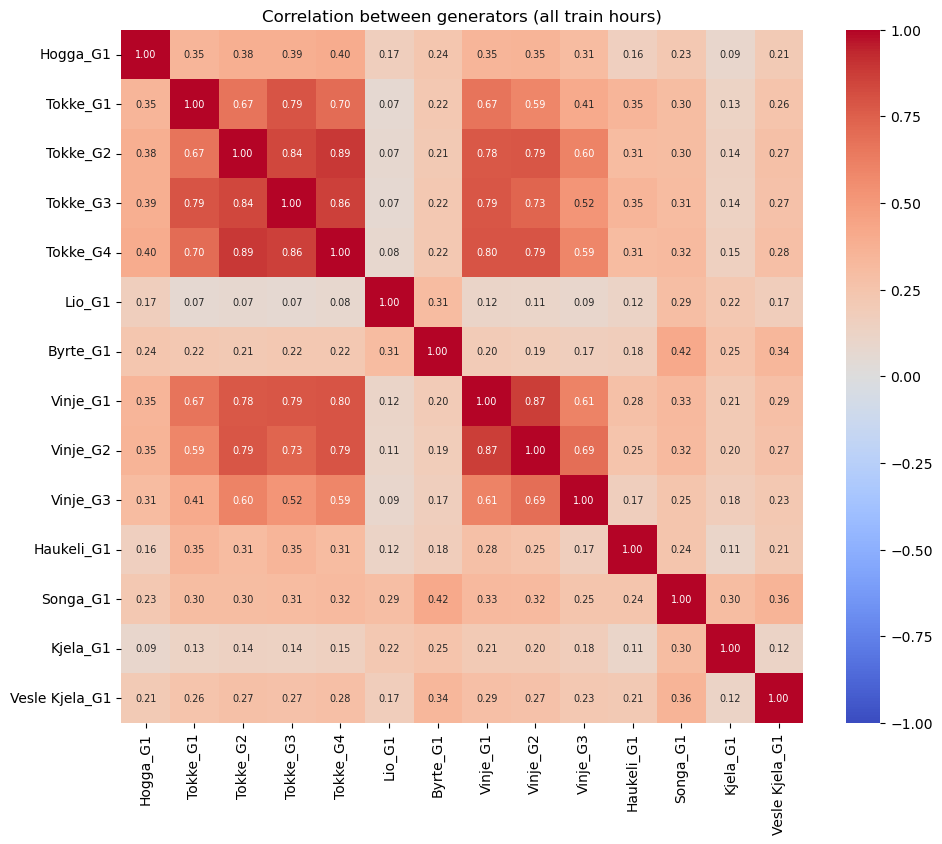

In [42]:
# Correlation plot: do generators switch ON together?
topo_order = list(topology["model"]["generator"])   # cascade order from the topology
flat = pd.DataFrame(Y.transpose(0, 2, 1).reshape(-1, len(gen_names)), columns=gen_names)[topo_order]
gen_corr = flat.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(gen_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation between generators (all train hours)")
plt.show()

**Notes 4.4**
- **Tokke and Vinje move together:** Tokke G2–G4 correlate 0.84–0.89 with each other, Vinje G1–G2 0.87, and Tokke ↔ Vinje 0.59–0.80. Vinje releases water into Vinjevatn, which is tiny (9.4 Mm³), and Tokke has to use it right away. They are effectively one coupled system.
- Lio is almost independent of Tokke (0.07). The small plants (Haukeli, Kjela, Vesle Kjela, Byrte, Songa) have low correlations (0.1–0.4) with the rest.
- There are no negative correlations: no generator is ON *instead of* another.
- → Tokke and Vinje could share features (or be predicted together). The others behave more independently.

### 4.5 Feature correlations

*Water values across reservoirs, volumes, inflows.*

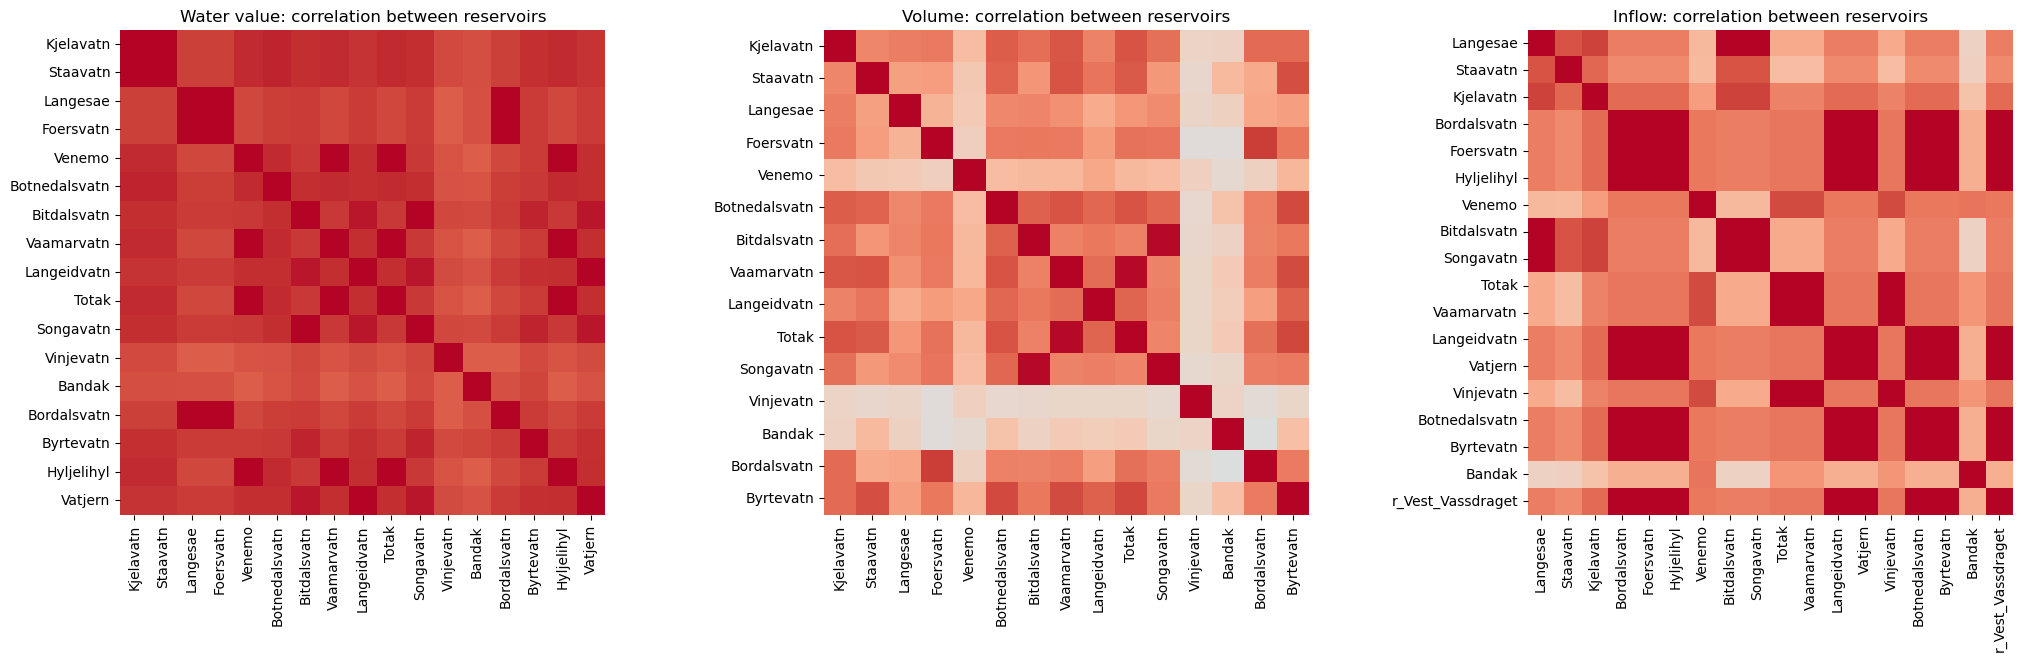

Water value pairs with corr = 1: 12 | lowest corr: 0.76
Volume  corr range: -0.0 to 0.99
Inflow  corr range: 0.14 to 1.0


In [43]:
# Correlation plots between input features
wv_corr = water_value.drop(columns="date").corr()
vol_corr = volume.drop(columns=["date", "Hyljelihyl", "Vatjern"]).corr()   # the two constant lakes have no correlation
inflow_corr = inflow.drop(columns="date").corr()

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, corr, title in zip(axes, [wv_corr, vol_corr, inflow_corr], ["Water value", "Volume", "Inflow"]):
    sns.heatmap(corr, ax=ax, cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar=False)
    ax.set_title(f"{title}: correlation between reservoirs")
plt.tight_layout()
plt.show()

upper = lambda c: c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack()
print("Water value pairs with corr = 1:", (upper(wv_corr) > 0.9999).sum(), "| lowest corr:", round(upper(wv_corr).min(), 2))
print("Volume  corr range:", round(upper(vol_corr).min(), 2), "to", round(upper(vol_corr).max(), 2))
print("Inflow  corr range:", round(upper(inflow_corr).min(), 2), "to", round(upper(inflow_corr).max(), 2))

**Notes 4.5**
- **Water value:** all reservoirs correlate ≥ 0.76, and **12 pairs are exactly 1** (duplicates, see 3.5). They all follow the same price level.
- **Volume:** much more varied (correlation 0 to 0.99). Vinjevatn and Bandak don't correlate with the other lakes, because they're kept at a fairly steady level (3.4).
- **Inflow:** large blocks with correlation ≈ 1. Several inflow series are scaled copies of the same series (not exact duplicates, see 3.3). Bandak and Venemo are the most different.
- → Many inputs are redundant. Deduplicate water values, and use a few representative inflow series (5.3).

### 4.6 Groups of target columns

*`df.mean().sort_values().plot(style='.')` over all 2352 target columns.*

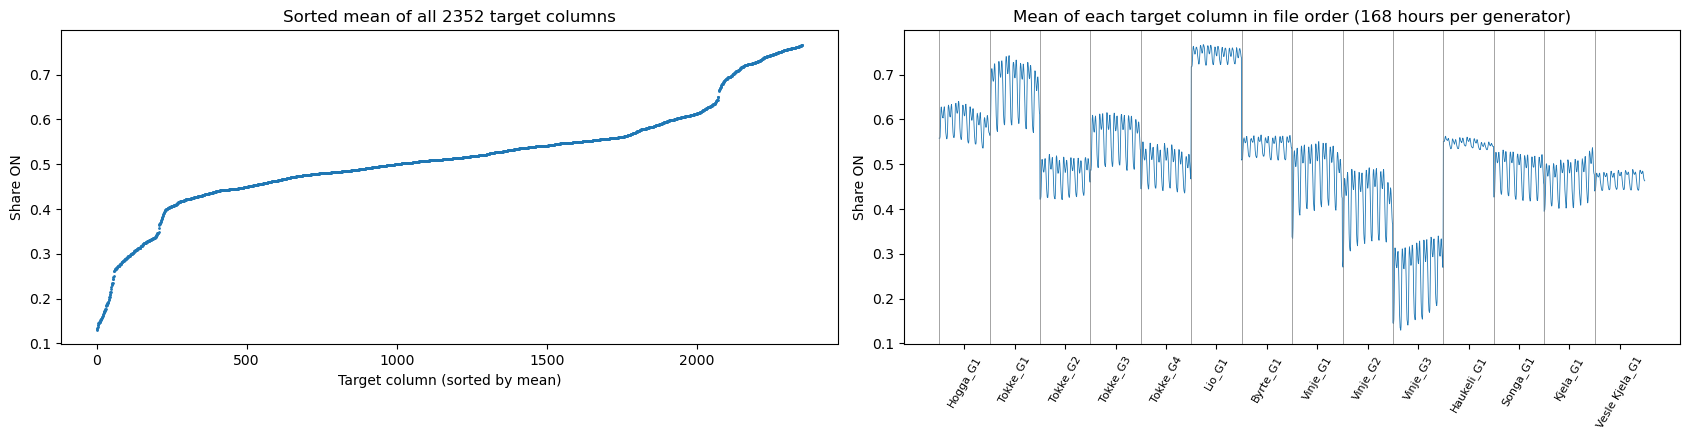

Column means range from 0.13 to 0.77; columns with mean < 0.05 or > 0.95: 0


In [44]:
# Plot of feature statistics: mean of each of the 2352 target columns
target_cols = [c for c in train.columns if c.startswith("result_committed_")]
col_means = train[target_cols].mean()

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))

# Sorted (lecture style): how many columns are rare / common?
col_means.sort_values().reset_index(drop=True).plot(style=".", ms=2, ax=axes[0])
axes[0].set_xlabel("Target column (sorted by mean)")
axes[0].set_ylabel("Share ON")
axes[0].set_title("Sorted mean of all 2352 target columns")

# Unsorted, in file order: blocks of 168 hours per generator
axes[1].plot(col_means.to_numpy(), lw=0.6)
for k in range(0, len(target_cols), 168):
    axes[1].axvline(k, color="grey", lw=0.5)
gen_in_file_order = [c.replace("result_committed_", "").rsplit("_t", 1)[0] for c in target_cols[::168]]
axes[1].set_xticks(np.arange(84, len(target_cols), 168))
axes[1].set_xticklabels(gen_in_file_order, rotation=60, fontsize=8)
axes[1].set_ylabel("Share ON")
axes[1].set_title("Mean of each target column in file order (168 hours per generator)")

plt.tight_layout()
plt.show()

print(f"Column means range from {col_means.min():.2f} to {col_means.max():.2f}; "
      f"columns with mean < 0.05 or > 0.95: {((col_means < 0.05) | (col_means > 0.95)).sum()}")

**Notes 4.6**
- **Sorted plot:** the column means increase smoothly from 0.13 to 0.77. No column is almost always 0 or 1, so every target column has both classes.
- **File-order plot:** each generator is a block of 168 hours with its own level (Lio highest, Vinje G3 lowest), so **the generator explains most of the difference between columns**.
- Inside each block you can see the **daily cycle** (3.1.2). It's strong for Tokke and Vinje and almost flat for Lio, Byrte and Haukeli.
- Some blocks (e.g. Vinje G1–G3, Tokke G2) dip at the very first hour (t0).

### 4.7 Train vs. test distribution shift

*Compare 2015–2022 with 2023–2024 for price, inflow, volume, water value.*

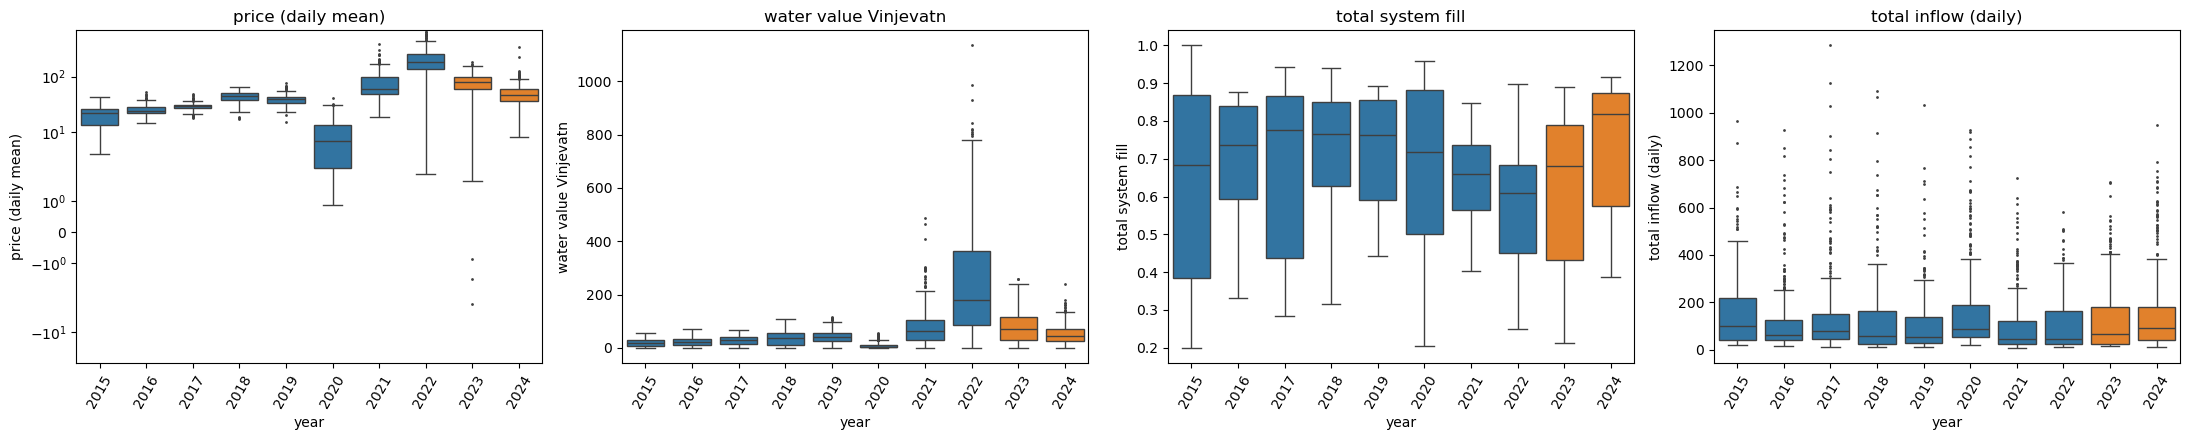

period,test 2023–24,train 2015–22
price (daily mean),59.17,31.70
water value Vinjevatn,53.65,29.58
total system fill,0.72,0.70
total inflow (daily),82.56,65.89


In [45]:
# Train vs test: compare the input features per year (box plots), test years in orange
daily = pd.DataFrame({
    "price (daily mean)": daily_price,
    "water value Vinjevatn": wv_s["Vinjevatn"],
    "total system fill": total_fill,
    "total inflow (daily)": inflow_total,
})
daily = daily[(daily.index.year >= 2015) & (daily.index.year <= 2024)]
daily["year"] = daily.index.year

fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
palette = {y: ("tab:orange" if y >= 2023 else "tab:blue") for y in range(2015, 2025)}
for ax, feat in zip(axes, daily.columns.drop("year")):
    sns.boxplot(data=daily, x="year", y=feat, hue="year", palette=palette, legend=False, ax=ax, fliersize=1)
    ax.set_title(feat)
    ax.tick_params(axis="x", rotation=60)
axes[0].set_yscale("symlog")
plt.tight_layout()
plt.show()

summary = daily.assign(period=np.where(daily["year"] >= 2023, "test 2023–24", "train 2015–22")) \
               .drop(columns="year").groupby("period").median().T.round(2)
summary

**Notes 4.7**
- **Price and water value shift up in test:** the median daily price is 59 (test) vs 32 (train), and the water value is 54 vs 30. Test isn't outside what train has seen, though: it looks like 2021 and is far below 2022. **Negative daily prices** only occur in 2023.
- **Hydrology does not shift much:** fill (median 0.72 vs 0.70) and inflow are similar to train. 2024 is a full, wet year (like 2015 and 2020).
- → The shift is mainly in the **price level**, which is why we use relative features (price − water value, price vs the week's mean). Validating on 2021 and 2022 checks how the model handles a different price level.

## 5. Data cleaning

### 5.0 Copy tables 

*Make copies of the input tables so they can be cleaned without affecting the originals*

In [48]:
# Make copies of the input tables so they can be cleaned without affecting the originals
tables = {"price": price, "inflow": inflow, "volume": volume, "water_value": water_value,
          "min_flow": min_flow, "min_volume": min_volume}

clean = {}                        
for name, df in tables.items():
    clean[name] = df.copy()      

### 5.1 Missing values

*`isnull()` per table; if any, understand why before imputing.*

In [49]:
# Check for null values
for name, df in clean.items():
    n_null = df.isnull().sum().sum()
    print(f"{name:12s} null values: {n_null}")

print(f"{'train':12s} null values: {train.isnull().sum().sum()}")

price        null values: 0
inflow       null values: 0
volume       null values: 0
water_value  null values: 0
min_flow     null values: 0
min_volume   null values: 0
train        null values: 0


### 5.2 Constant features

*A column with only one distinct value (`nunique() == 1`) carries no information and can be dropped. Here we check every input table (price, inflow, volume, water value, min flow, min volume) for such columns*

In [55]:
for name, df in clean.items():
    n_unique = df.drop(columns="date").nunique()   # number of different values per column
    constant = n_unique[n_unique == 1].index.tolist()
    print(f"{name:12s} constant columns: {constant}")

# Clean: drop the constant columns
clean["volume"] = clean["volume"].drop(columns=["Hyljelihyl", "Vatjern"], errors="ignore")

price        constant columns: []
inflow       constant columns: []
volume       constant columns: ['Hyljelihyl', 'Vatjern']
water_value  constant columns: []
min_flow     constant columns: []
min_volume   constant columns: []


**Notes 5.2**
- Only `volume` has constant columns: Hyljelihyl and Vatjern (no records, fixed at 50% full). They are dropped as features.
- No min-flow or min-volume constraint is always 0, so every constraint is active at some point.

### 5.3 Duplicated features

A column that is an exact copy of another column adds no information. We check every input table for duplicated columns, and keep one column per group.

#### 5.3.1 Check every table for duplicates 


In [53]:
# Each column gets a "fingerprint" made from all its values; identical columns get identical fingerprints.
# (Faster than df.T.duplicated(), which is very slow for tables with many rows.)
for name, df in clean.items():
    cols = df.drop(columns="date")
    fingerprint = cols.apply(lambda s: hash(s.to_numpy().tobytes()))
    print(f"{name:12s} duplicated columns: {fingerprint.duplicated().sum()}")

price        duplicated columns: 0
inflow       duplicated columns: 0
volume       duplicated columns: 0
water_value  duplicated columns: 8
min_flow     duplicated columns: 0
min_volume   duplicated columns: 0


In [54]:
remaining = clean["water_value"].drop(columns="date")
n_dup_left = remaining.apply(lambda s: hash(s.to_numpy().tobytes())).duplicated().sum()
print("Columns left:", remaining.shape[1], "| duplicates left:", n_dup_left)

Columns left: 17 | duplicates left: 8


#### 5.3.2 Remove duplicated water value columns 

In [56]:
# 1. Find groups of identical water value columns.
#    Use the ORIGINAL table, so the cell gives the same result if it is run twice.
wv_cols = water_value.drop(columns="date")

groups = {}
for col in wv_cols.columns:
    groups.setdefault(tuple(wv_cols[col]), []).append(col)
groups = list(groups.values())

print(f"water_value: {wv_cols.shape[1]} columns, only {len(groups)} distinct")
for cols in groups:
    if len(cols) > 1:
        print(f"  keep {cols[0]:12s} drop {cols[1:]}")

# 2. Lookup: for every lake, which column holds its water value after cleaning
#    (e.g. Vinje takes water from Vaamarvatn -> use the column 'Venemo')
wv_alias = {col: cols[0] for cols in groups for col in cols}

# 3. Clean: drop the copies
drop = [col for cols in groups for col in cols[1:]]
clean["water_value"] = clean["water_value"].drop(columns=drop, errors="ignore")

# 4. Verify
remaining = clean["water_value"].drop(columns="date")
n_dup_left = remaining.apply(lambda s: hash(s.to_numpy().tobytes())).duplicated().sum()
print("Columns left:", remaining.shape[1], "| duplicates left:", n_dup_left)
print("Every generator's lake can still be found:",
      all(wv_alias[upstream[gen]] in remaining.columns for gen in upstream))

water_value: 17 columns, only 9 distinct
  keep Kjelavatn    drop ['Staavatn']
  keep Langesae     drop ['Foersvatn', 'Bordalsvatn']
  keep Venemo       drop ['Vaamarvatn', 'Totak', 'Hyljelihyl']
  keep Bitdalsvatn  drop ['Songavatn']
  keep Langeidvatn  drop ['Vatjern']
Columns left: 9 | duplicates left: 0
Every generator's lake can still be found: True


### 5.4 Duplicated rows / timestamps

*Duplicate or missing hours.*

In [57]:
# Check the time axis of every table: one row per time step, in order, no duplicates
for name, df in clean.items():
    d = df["date"]
    steps = d.diff().value_counts()
    print(f"{name:12s} tz={d.dt.tz}  duplicate timestamps={d.duplicated().sum()}  "
          f"sorted={d.is_monotonic_increasing}  steps={dict(steps)}")

print(f"\ntrain        duplicate Run No={train['Run No'].duplicated().sum()}  "
      f"duplicate starttime={train['starttime'].duplicated().sum()}")

price        tz=UTC  duplicate timestamps=0  sorted=True  steps={Timedelta('0 days 01:00:00'): 94222, Timedelta('0 days 00:15:00'): 8839}
inflow       tz=UTC  duplicate timestamps=0  sorted=True  steps={Timedelta('0 days 01:00:00'): 594223}
volume       tz=UTC  duplicate timestamps=0  sorted=True  steps={Timedelta('1 days 00:00:00'): 3653}
water_value  tz=UTC  duplicate timestamps=0  sorted=True  steps={Timedelta('1 days 00:00:00'): 3653}
min_flow     tz=UTC  duplicate timestamps=0  sorted=True  steps={Timedelta('0 days 01:00:00'): 96431}
min_volume   tz=UTC  duplicate timestamps=0  sorted=True  steps={Timedelta('0 days 01:00:00'): 96431}

train        duplicate Run No=0  duplicate starttime=0


**Notes 5.4**
- All tables: no duplicate timestamps, sorted in time order, and a constant step (hourly or daily) → no gaps.
- Price: hourly up to 2025-09-30, then 15-minute steps from 2025-09-30 22:15 (outside our period; trimmed in 5.6). 0 missing hours in 2015–2024.
- `train`: no duplicate runs (Run No and starttime unique).
- All timestamps are UTC, so there are no daylight-saving gaps or doubled hours. Conversion to Oslo time is handled in 5.6.
- Nothing to clean here.

### 5.5 Outliers

*Box plots, Z-score, IQR. Decide: real (keep) or error (fix/remove).*

#### 5.5.1 Box plots 

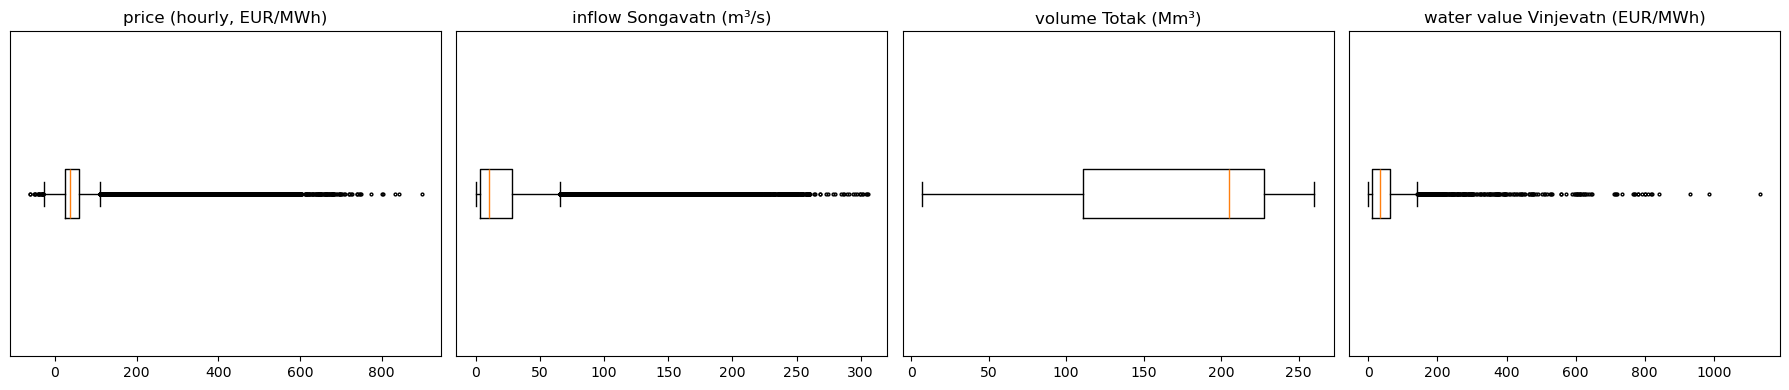

In [58]:
# Box plots: median (line), middle 50% (box), whiskers = Q1 − 1.5·IQR and Q3 + 1.5·IQR, dots = outliers
features = {
    "price (hourly, EUR/MWh)": clean["price"].loc[clean["price"]["date"] < "2025-01-01", "Day-ahead price (EUR/MWh)"],
    "inflow Songavatn (m³/s)": clean["inflow"]["Songavatn"],
    "volume Totak (Mm³)": clean["volume"]["Totak"],
    "water value Vinjevatn (EUR/MWh)": clean["water_value"]["Vinjevatn"],
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, s) in zip(axes, features.items()):
    ax.boxplot(s, vert=False, flierprops={"markersize": 2})
    ax.set_title(name)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

#### 5.5.2 Count outliers with Z-score and IQR

In [61]:
def outlier_stats(s):
    z = (s - s.mean()) / s.std()                       # Z-score: how many std from the mean
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1                                       # middle 50%
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr       # the whiskers in the box plot
    is_out = (s < lower) | (s > upper)
    return {
        "% |z| > 3": 100 * (z.abs() > 3).mean(),
        "% outside IQR fences": 100 * is_out.mean(),
        "lower fence": lower, "upper fence": upper, "max": s.max(),
    }

pd.DataFrame({name: outlier_stats(s) for name, s in features.items()}).T.round(2)

price (hourly, EUR/MWh)          outliers mostly in: {2022: 7429, 2021: 1329, 2023: 1234}
inflow Songavatn (m³/s)          outliers mostly in: {1967: 1680, 1997: 1494, 2005: 1381}
volume Totak (Mm³)               outliers mostly in: {}
water value Vinjevatn (EUR/MWh)  outliers mostly in: {2022: 220, 2021: 62, 2023: 58}


#### 5.5.3 Which years do the IQR outliers come from?

In [62]:
for name, s in features.items():
    dates = clean["price"]["date"] if name.startswith("price") else \
            clean["inflow"]["date"] if name.startswith("inflow") else \
            clean["volume"]["date"] if name.startswith("volume") else clean["water_value"]["date"]
    dates = dates.loc[s.index]
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    is_out = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    top_years = dates[is_out].dt.year.value_counts().head(3).to_dict()
    print(f"{name:32s} outliers mostly in: {top_years}")


price (hourly, EUR/MWh)          outliers mostly in: {2022: 7429, 2021: 1329, 2023: 1234}
inflow Songavatn (m³/s)          outliers mostly in: {1967: 1680, 1997: 1494, 2005: 1381}
volume Totak (Mm³)               outliers mostly in: {}
water value Vinjevatn (EUR/MWh)  outliers mostly in: {2022: 220, 2021: 62, 2023: 58}


**Notes 5.5**
- **Box plots** show long upper tails for price, inflow and water value. Volume has no outliers (lakes have a fixed size).
- **Z-score (|z| > 3):** 2–3% of values for price, inflow and water value; 0% for volume.
- **IQR (outside the whiskers):** about 10–12% of values. That's far more than errors would explain, because these features are strongly right-skewed (section 3).
- **Where they are:** price and water value outliers are mostly in **2022** (the energy crisis); inflow outliers are in **flood years / snowmelt**.
- **Decision: keep all of them.** They are real events, not measurement errors, and they matter for the decisions (2022 had the fewest generators ON, 3.1.3).
  Physically impossible values were already checked in 2.3.1 (none found; volume above max_vol is real flooding).
- **How we handle them instead of removing them:** relative price features (price − water value, price vs the week's mean) reduce the effect of the extreme price level, and tree models (LightGBM) are not sensitive to outliers.

### 5.6 Time alignment

*The tables have different time steps (hourly vs daily) and each run covers 168 hours. Here we make the price hourly everywhere, decide on one time zone, and check that every run (train and test) can look up all the values it needs.*

#### One time zone (UTC), with Oslo time as an extra column

In [63]:
# For every run (train and test), look up the information it needs, then check that nothing is missing.
# Rules for a run starting on day d:
#   hourly tables (price, inflow, min flow) -> the 168 hours from d 00:00 UTC
#   volume                                  -> day d (start day only; later volumes would be cheating)
#   water value                             -> day d + 7 (the end-of-week value, see 4.2)

def naive_index(df):
    """Use the date as index and drop the UTC label, so it can be compared with starttime."""
    return df.set_index(df["date"].dt.tz_convert(None)).drop(columns="date")

def hourly_matrix(df, col, starts):
    """Values of one column for the 168 hours of every run: shape (runs, 168)."""
    s = naive_index(df)[col]
    hours = starts.to_numpy()[:, None] + np.arange(168) * np.timedelta64(1, "h")
    return s.reindex(hours.ravel()).to_numpy().reshape(len(starts), 168)

# All runs: train and test together
runs = pd.concat([train[["Run No", "starttime"]].assign(set="train"),
                  test[["Run No", "starttime"]].assign(set="test")], ignore_index=True)
starts = runs["starttime"]

# Look up the information for every run
price_h = hourly_matrix(clean["price"], "Day-ahead price (EUR/MWh)", starts)
inflow_h = hourly_matrix(clean["inflow"], "Songavatn", starts)
minflow_h = hourly_matrix(clean["min_flow"], "b_Bandak", starts)
vol_start = naive_index(clean["volume"]).reindex(starts)
wv_end = naive_index(clean["water_value"]).reindex(starts + pd.Timedelta(days=7))

# Check: is anything missing for any run?
pd.DataFrame({
    "runs": runs.groupby("set").size(),
    "missing price hours": pd.Series(np.isnan(price_h).sum(axis=1)).groupby(runs["set"]).sum(),
    "missing inflow hours": pd.Series(np.isnan(inflow_h).sum(axis=1)).groupby(runs["set"]).sum(),
    "missing min-flow hours": pd.Series(np.isnan(minflow_h).sum(axis=1)).groupby(runs["set"]).sum(),
    "missing start-day volume": pd.Series(vol_start.isna().any(axis=1).to_numpy()).groupby(runs["set"]).sum(),
    "missing water value d+7": pd.Series(wv_end.isna().any(axis=1).to_numpy()).groupby(runs["set"]).sum(),
})

,runs,missing price hours,missing inflow hours,missing min-flow hours,missing start-day volume,missing water value d+7
set,,,,,,
test,725,0,0,0,0,0
train,2922,0,0,0,0,0


**Notes 5.6**
- The tables have different time steps: price, inflow and constraints are hourly, volume and water value are daily, and each run covers 168 hours.
- All tables are in UTC, so there are no daylight-saving gaps or doubled hours. `starttime` is treated as 00:00 UTC.
- Rules for a run starting on day d:
  - hourly tables → the 168 hours from d 00:00,
  - volume → day d only (later volumes are a result of the plan, so using them would be cheating),
  - water value → day d + 7 (the end-of-week value, 4.2).
- Price's 15-minute rows (from 2025-09-30) are never used, since runs only need hours up to 2024-12-31 23:00.
- Check: all 2922 train runs and all 725 test runs get every value they need (0 missing).

## 6. Key findings & implications for modelling

### 6.1 Key findings

**The data**
- **Clean and complete:** no missing values, duplicate timestamps or gaps in 2015–2024. All 2922 train runs and 725 test runs get every input they need (5.1, 5.4, 5.6).
- **One run per day:** `starttime = 2015-01-01 + (Run No − 1) days`, so test = 2023-01-01 → 2024-12-25 (2.2.2).
- **Many inputs are redundant:** water value has only 9 distinct series in 17 columns, several inflow series are scaled copies of each other, and the Hyljelihyl and Vatjern volumes are constant (4.5, 5.2, 5.3).
- **Outliers are real events, not errors:** the 2022 price crisis, floods, and volumes briefly above `max_vol`. They are kept (2.3.1, 5.5).

**The target**
- The labels come from an optimiser (SHOP), and they follow hydropower logic: ON when price > water value, more ON in expensive hours and in the daytime (2.3.2).
- **Balanced classes:** 0.516 ON overall, from 0.26 (Vinje G3) to 0.75 (Lio G1). Every target column has both classes (3.1.1, 4.6).
- **Sticky decisions:** only 1.2% of hours switch ON↔OFF, and in 59% of runs a unit never switches during the week. This fits the start costs (92–222) (2.3.2, 3.7).
- **Daily cycle, no horizon effect:** the ON share follows the price (high at 08–10 and 18–19, low at 02–04). There's no trend over t0–t167, and agreement between consecutive runs is flat at ≈ 88% across the horizon (2.2.1, 3.1.2).
- **Priority order inside a plant:** the Tokke and Vinje units are identical, yet G1 is used first (Vinje G1 0.49 > G2 0.42 > G3 0.26) (3.1.1, 3.7).
- **Tokke and Vinje are one coupled system:** they correlate at 0.59–0.89 and are the least stable units (≈ 82% agreement between runs). The small plants are more independent and stable (≈ 95%) (2.2.1, 4.4).
- **Years differ, months don't:** the ON share drops from 0.63 (2018) to 0.34 (2022), and each unit's behaviour changes a lot between years (3.1.3).
- **Some labels may be noisy:** slow solver runs come in clusters, with a spike at ≈ 1000 s (probably a time limit), and are worst in late 2022 (2.2.3).

**The features**
- **Price − upstream water value (at start + 7 days) is by far the strongest signal:** AUC 0.76–0.99 per unit on its own, vs 0.39–0.56 for raw price (4.2).
- **Raw price level says nothing on its own:** the correlation between a week's mean price and its ON share is −0.27. Relative price within the week does explain the ON share (4.1).
- **Water value ≈ c × next week's mean price** (correlation 0.84, c between 0 and 2), so the water value already carries the price level (3.5).
- **Each unit's own upstream lake matters:** Songa is ON 19% of the time in the emptiest 10% of weeks and 93% in the fullest. Total system fill and inflow are weak (0.24 and 0.17) (4.3).
- **Constraints follow a fixed seasonal calendar.** Totak min volume (Jul–Nov) may limit Vinje (3.6).

**Train vs test**
- **The shift is in the price level:** test has a median price of 59 vs 32 in train, a water value of 54 vs 30, and 380 negative-price hours vs 10 in train. Test still lies within what train has seen (between 2021 and 2022) (2.3.1, 3.2, 4.7).
- **Hydrology is similar:** fill is 0.72 vs 0.70, and 2024 is a wet year like 2015 and 2020 (3.3, 4.7).

### 6.2 Implications for modelling

**Validation**
- Validate by year (2020, 2021, 2022) with a ≥ 7-day embargo. Never use random K-fold, because neighbouring runs overlap by 6 of 7 days, which would leak answers (2.2.1).
- The three years cover a wet year (2020), a test-like price level (2021) and the crisis (2022). Report each year separately, since 2022 is extreme and may have noisier labels.
- Always score with `kaggle_metric.score()` (micro ROC-AUC).

**Features** (long format: one row per run × unit × hour)
- **Core:** price − the unit's upstream water value at d + 7, plus price / water value.
- **Relative price:** price compared with the week's mean and std, and the rank of the hour within the week and within the day. Don't use raw EUR on its own.
- **Unit:** unit ID, plant, order within the plant (G1, G2, …), p_min, p_max and start cost.
- **Own upstream lake:** fill on the start day (volume / `max_vol`) and inflow over the week (log-transformed).
- **Time:** hour of day (Oslo time), weekday, and day of year (sin/cos). Totak min-volume flag.
- **Context for stickiness:** price − water value in the neighbouring hours, and the number of hours in the day or week where price > water value, so the model can predict blocks rather than single hours.
- **Tokke–Vinje:** shared features (the Vinjevatn and Vaamarvatn state, and the other plant's price − water value).
- **Drop or never use:** `total_calculation_time`, volumes after the start day, the constant Hyljelihyl and Vatjern volumes, and the duplicated water value columns.

**Model**
- **Baseline:** price − water value alone (AUC 0.76–0.99). Every model must beat this.
- **Main model:** LightGBM on the long format (float32, subsample rows while iterating). Trees handle the skewed features and outliers without scaling.
- **Optional post-processing:** smooth the probabilities over neighbouring hours within a run, and keep it only if validation improves.
- **Spend effort on Tokke and Vinje:** they have the weakest single-feature AUC and the least stable labels.
- **Micro-AUC ranks all units together:** no class weights are needed (the classes are balanced). Never use per-unit weights or rank-normalise per unit, and blend raw probabilities with global weights.
- **Possible label noise:** test whether down-weighting the slow 2022 runs helps on validation.

**Submission**
- Column order is unit-major (`<Plant>_<Unit>_t0..t167`), and `Vesle Kjela` contains a space. Check 725 rows, identical columns to `sample_submission.csv`, values in [0, 1] and no NaN before uploading.